# Diseño Robusto mediante Metodología de Taguchi ($L_{16}$): Optimización de la Resistencia a Compresión de Lechadas de Cemento Reforzadas con Aditivos

**Materia:** Diseño de Experimentos (DOE)  
**Contexto Experimental:** Optimización de lechadas de cemento con 3 factores controlables a 4 niveles (`bentonita`, `cenizas_volantes`, `humos_silice`) evaluadas a 7, 14 y 28 días de curado  
**Referencias Teóricas y Metodológicas:**
1. **Gutiérrez Pulido, H., & De la Vara Salazar, R.** (2008). *Análisis y Diseño de Experimentos* (2.ª Edición, **Capítulo 9: Introducción al diseño robusto - Taguchi**, págs. 294–317). McGraw-Hill Interamericana.
2. **Tan, Ö., & Sahin Zaimoglu, A.** (2007). *Optimización de la resistencia a compresión de lechadas de cemento reforzadas con aditivos* (*Optimization of compressive strength in admixture-reinforced cement-based grouts*). **Materiales de Construcción**, Vol. 57, N.º 288, págs. 91–98. ISSN: 0465-2746.

---

### Objetivos Científicos y de Ingeniería del Experimento

1. **Fundamentar teóricamente el Diseño Robusto de Parámetros (Metodología de Taguchi)** a partir del Capítulo 9 de Gutiérrez Pulido & De la Vara Salazar: filosofía de calidad fuera de línea (*off-line QC*), función de pérdida cuadrática $L(y)$, clasificación de factores de control (Clases I, II, III y IV), tipos de ruido y arreglos ortogonales.
2. **Estructurar y auditar el conjunto de datos experimentales de la Tabla 3** del artículo de Tan & Zaimoglu (2007), compuesto por un **Arreglo Ortogonal $L_{16} (4^3)$** con **3 factores de control** (`bentonita`, `cenizas_volantes`, `humos_silice`) en 4 niveles cada uno y 3 réplicas por combinación a los 7, 14 y 28 días de curado ($N = 16 \times 3 = 48$ observaciones por edad; $144$ mediciones en el arreglo más $12$ de referencia en la Tabla 4).
3. **Ejecutar el Paso 1 de Taguchi — Análisis Estadístico de la Razón Señal/Ruido ($S/R$)**: aplicar el criterio *"Mientras más grande es mejor"* (*Larger-the-better*), auditar la Tabla 5 y la Tabla 6 del artículo, y construir las **Gráficas de Efectos Principales para $S/R$**.
4. **Ejecutar el Paso 2 de Taguchi — Análisis de la Media de la Respuesta ($\bar{Y}$) y de la Variabilidad ($-10\log_{10} S^2$)**: obtener las tablas de respuesta para la media, construir las **Gráficas de Efectos Principales para la Media ($\bar{Y}$)**, evaluar la relación media-desviación estándar $(\bar{Y}_i, S_i)$ de Fowlkes & Creveling y clasificar cada factor en las Clases I a IV.
5. **Desarrollar el Análisis de Varianza (ANOVA) Completo y el Mejor ANOVA (*Pooling*)**: reconstruir íntegramente la Tabla 7 (incluyendo el bloque de 28 días truncado en la edición impresa del PDF), calcular los porcentajes de contribución $P(\%)$, formular el ANOVA para la media $\bar{Y}$ y aplicar el agrupamiento (*pooling*) del factor inerte (`bentonita`) hacia el error residual ($\text{GL}_E = 9$).
6. **Validar la Predicción en los Niveles Óptimos Seleccionados y su Intervalo de Confianza (Tabla 8)**: demostrar analíticamente que para la combinación óptima **`bentonita = B_0.0%`**, **`cenizas_volantes = CV_10%`** y **`humos_silice = HS_20%`**, el valor predicho de la razón $S/R$ a 28 días es exactamente **`24.8327 dB`** (equivalente a **`17.4435 MPa`** $\approx 17.44\text{ MPa}$), verificando los intervalos de confianza al $90\%$ y las pruebas de confirmación experimental.
7. **Diagnosticar exhaustivamente los supuestos estadísticos del modelo**: validar normalidad (Shapiro-Wilk y Q-Q Plot), homocedasticidad e independencia de los residuos tanto para $S/R$ como para la media $\bar{Y}$.

In [14]:
# ==============================================================================
# CONFIGURACIÓN DEL ENTORNO CIENTÍFICO Y ESTILO GRÁFICO PROFESIONAL (DARK THEME)
# ==============================================================================
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import scipy
import scipy.stats as stats
import statsmodels.api as sm
from statsmodels.formula.api import ols
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns

# Configuración estética de publicación (Dark Theme de alto contraste)
plt.style.use('dark_background')
plt.rcParams.update({
    'font.family': 'sans-serif',
    'font.sans-serif': ['DejaVu Sans', 'Arial', 'Helvetica'],
    'axes.facecolor': '#0F172A',
    'figure.facecolor': '#0B1120',
    'axes.edgecolor': '#475569',
    'axes.linewidth': 1.2,
    'grid.color': '#334155',
    'grid.linestyle': '--',
    'grid.alpha': 0.55,
    'figure.titlesize': 14,
    'figure.titleweight': 'bold',
    'axes.titlesize': 12,
    'axes.titleweight': 'bold',
    'axes.labelsize': 11,
    'axes.labelweight': 'bold',
    'xtick.labelsize': 10,
    'ytick.labelsize': 10,
    'legend.fontsize': 9.5,
    'figure.dpi': 140
})

PALETTE = {
    'cyan': '#00E5FF',      # Señal/Ruido (S/R) / Factor dominante
    'emerald': '#00E676',   # Óptimo / Confirmación / Humo de sílice
    'amber': '#FFD600',     # Alertas / Media global / Predicción
    'coral': '#FF5252',     # Efecto reductor / Cenizas volantes
    'purple': '#B388FF',    # Media de la respuesta / Modelos
    'slate': '#94A3B8',     # Factor inerte (Bentonita) / Referencia
    'blue': '#38BDF8',      # Curvas secundarias
    'card': '#1E293B'       # Fondo de cajas de anotación
}

pd.set_option('display.max_columns', 25)
pd.set_option('display.width', 1000)
pd.set_option('display.precision', 4)

print("Entorno científico inicializado correctamente.")
print(f"NumPy {np.__version__} | Pandas {pd.__version__} | SciPy {scipy.__version__} | Statsmodels {sm.__version__}")

Entorno científico inicializado correctamente.
NumPy 2.4.6 | Pandas 3.0.6 | SciPy 1.17.1 | Statsmodels 0.15.0


---
## SECCIÓN 1: Marco Teórico del Diseño Robusto — Metodología de Taguchi (Gutiérrez & De la Vara, Cap. 9)

### 1.1 Filosofía de Calidad de Taguchi y el Concepto de Robustez
El ingeniero japonés **Genichi Taguchi** revolucionó la ingeniería de calidad al introducir el **Control de Calidad Fuera de Línea (*Off-line Quality Control*)**, postulando que la inspección en planta es insuficiente y que la calidad competitiva debe inyectarse desde la fase de diseño del producto y del proceso (Gutiérrez Pulido & De la Vara Salazar, Cap. 9, págs. 296–298).

* **Calidad según Taguchi:** Se mide en términos de abatir al mínimo las pérdidas que un producto causa a la sociedad desde su fabricación hasta que concluye su ciclo de vida útil.
* **Diseño Robusto (Diseño de Parámetros):** Es un experimento en el que existen **factores de ruido** (variables no controlables a escala industrial o ambiental, consideradas de forma explícita en un arreglo externo o implícita mediante repeticiones funcionales) cuyo efecto adverso se busca minimizar de manera indirecta eligiendo la combinación óptima de los niveles de los **factores de control** (parámetros del sistema).
* **Tres etapas del desarrollo en Ingeniería de Calidad:**
  1. **Diseño del sistema:** Configuración tecnológica y científica básica (en nuestro caso, la matriz de cemento Portland CEM I con adiciones minerales puzolánicas y arcillosas).
  2. **Diseño de parámetros (Diseño Robusto):** Selección de las proporciones óptimas de los aditivos (`bentonita`, `cenizas_volantes`, `humos_silice`) que maximizan la resistencia mecánica y minimizan la sensibilidad a la variabilidad.
  3. **Diseño de tolerancias:** Fijación de márgenes de tolerancia estrechos únicamente en los parámetros críticos.

---

### 1.2 Función de Pérdida Cuadrática de Taguchi $L(y)$
A diferencia del enfoque tradicional por intervalos de especificación $[EI, ES]$ (tipo escalón "pasa / no pasa"), Taguchi modela la pérdida económica y social mediante una función continua cuadrática:

1. **Característica Nominal es lo Mejor** (con valor objetivo o *target* $t$):
   $$L(y) = k (y - t)^2$$
   Para una muestra de $n$ unidades con media $\bar{y}$ y varianza muestral $S^2$, la pérdida promedio esperada es:
   $$\bar{L} = \frac{1}{n}\sum_{i=1}^n k(y_i - t)^2 = k \left[ \frac{n-1}{n}S^2 + (\bar{y} - t)^2 \right] \approx k \left[ S^2 + (\bar{y} - t)^2 \right]$$

2. **Característica Mientras más Pequeña es Mejor** ($t = 0$):
   $$L(y) = k y^2 \implies \bar{L} = k \left(\frac{1}{n}\sum_{i=1}^n y_i^2\right)$$

3. **Característica Mientras más Grande es Mejor** ($t \to \infty$, como la **resistencia a compresión** $Y$ en MPa):
   $$L(y) = k \left(\frac{1}{y^2}\right) \implies \bar{L} = k \left(\frac{1}{n}\sum_{i=1}^n \frac{1}{y_i^2}\right) = k \cdot \text{MSD}$$
   Donde $\text{MSD} = \frac{1}{n}\sum_{i=1}^n \frac{1}{y_i^2}$ es la desviación cuadrática media inversa (*Mean Squared Deviation*). Minimizar la pérdida esperada $\bar{L}$ equivale directamente a minimizar $\text{MSD}$ o, en escala logarítmica de decibeles, **maximizar la Razón Señal/Ruido ($S/R$)**.

---

### 1.3 Clasificación de los Factores de Control (Clases I, II, III y IV) y Factores de Ruido
De acuerdo con la **Figura 9.3** de Gutiérrez Pulido & De la Vara Salazar (págs. 299–302), los factores controlables se clasifican según su impacto sobre la **Media ($\bar{Y}$)** y sobre la **Variabilidad ($S/R$)**:

| Clase de Factor | Efecto sobre la Media ($\bar{Y}$) | Efecto sobre la Variabilidad ($S/R$) | Rol en la Estrategia de Optimización de Taguchi |
| :--- | :---: | :---: | :--- |
| **Clase I** | **Sí afecta** | **Sí afecta** | Factor crítico dual: se fija en el nivel que maximiza la razón $S/R$ (y simultáneamente favorece la media). |
| **Clase II** | No afecta | **Sí afecta** | Factor de robustez pura: interactúa con el ruido; se selecciona su nivel para minimizar la varianza. |
| **Clase III** | **Sí afecta** | No afecta | **Factor de ajuste (*scaling/adjustment factor*):** permite desplazar la media $\bar{Y}$ hacia el valor objetivo sin alterar la variabilidad. |
| **Clase IV** | No afecta | No afecta | **Factor inerte o de costo:** se fija en el nivel más económico, ecológico o funcionalmente conveniente (y se agrupa al error en el ANOVA mediante *pooling*). |

Por su parte, los **factores de ruido** se dividen en:
* **Ruido externo:** Condiciones ambientales (humedad, temperatura de curado, variabilidad operativa en el mezclado/inyección).
* **Ruido interno:** Variación intrínseca de unidad a unidad (heterogeneidad granulométrica de las partículas de cemento, ceniza volante, humo de sílice y bentonita entre probetas).
* **Deterioro:** Degradación o evolución físico-química con el paso del tiempo.

---

### 1.4 Razón Señal/Ruido ($S/R$) y Estrategia de Optimización en Dos Pasos
La **Tabla 9.2** del libro de referencia (pág. 308) y las **Ecuaciones [1]–[3]** del artículo de Tan & Zaimoglu (2007) definen las métricas $S/R$ (expresadas en decibeles, $\text{dB}$):

$$\begin{aligned}
\text{1. Mientras más grande es mejor (Ec. [1]):} \quad & S/R_{\text{L}} = \eta = -10 \log_{10} \left[ \frac{1}{n} \sum_{i=1}^n \frac{1}{Y_i^2} \right] \\[6pt]
\text{2. Mientras más pequeña es mejor (Ec. [2]):} \quad & S/R_{\text{S}} = -10 \log_{10} \left[ \frac{1}{n} \sum_{i=1}^n Y_i^2 \right] \\[6pt]
\text{3. Nominal es lo mejor — Tipo I:} \quad & S/R_{\text{N1}} = 10 \log_{10} \left( \frac{\bar{Y}^2}{S^2} \right) \\[6pt]
\text{4. Nominal es lo mejor — Tipo II (Variabilidad general, libro pág. 309):} \quad & S/R_{\text{N2}} = -10 \log_{10} \left( S^2 \right)
\end{aligned}$$

> **¿Por qué se diseña siempre para maximizar $S/R$?**  
> El signo negativo en $-10\log_{10}(\text{MSD})$ garantiza que, sin importar cuál sea el criterio de calidad, **el tratamiento más robusto siempre es aquel que maximiza algebraicamente el valor de $S/R$**. Además, la transformación logarítmica favorece la aditividad de los efectos principales y atenúa interacciones espurias (Gutiérrez & De la Vara, pág. 308).

#### Estrategia de Optimización en Dos Pasos (Gutiérrez & De la Vara, pág. 309):
* **Paso 1 (Análisis de $S/R$):** Identificar los factores activos sobre el estadístico $S/R$ mediante gráficas de efectos principales y ANOVA, seleccionando los niveles que **maximizan $S/R$**.
* **Paso 2 (Análisis de la Media $\bar{Y}$):** Realizar el análisis estadístico y gráfico para la respuesta promedio $\bar{Y}$, verificando la consistencia entre la maximización de $S/R$ y la maximización de $\bar{Y}$, y complementando con el análisis de $-10\log_{10}(S^2)$ y el diagrama de dispersión $(\bar{Y}_i, S_i)$ de Fowlkes & Creveling.

---
## SECCIÓN 2: Diseño Experimental $L_{16} (4^3)$, los 3 Factores de Control y Datos de la Tabla 3

### 2.1 Materiales y Definición de los 3 Factores en 4 Niveles (Tablas 1 y 2)
El estudio experimental de Tan & Zaimoglu (2007) evalúa la resistencia a la compresión simple (no confinada, norma ASTM C109) de probetas cilíndricas ($38\text{ mm} \times 76\text{ mm}$, relación agua/cemento $= 0.75$, amasado a $1000\text{ rpm}$ durante $5\text{ min}$) de lechadas de inyección elaboradas con cemento Portland CEM I reforzado con **3 factores (aditivos minerales en porcentaje en peso del sólido)**, cada uno estudiado en **4 niveles**:

| Nivel Codificado | Factor 1: `bentonita` ($B$, %) | Factor 2: `cenizas_volantes` ($CV / FA$, %) | Factor 3: `humos_silice` ($HS / SF$, %) |
| :---: | :---: | :---: | :---: |
| **Nivel 1** | `B_0.0%` ($0.0\%$) | `CV_10%` ($10\%$) | `HS_0%` ($0\%$) |
| **Nivel 2** | `B_0.5%` ($0.5\%$) | `CV_20%` ($20\%$) | `HS_5%` ($5\%$) |
| **Nivel 3** | `B_1.0%` ($1.0\%$) | `CV_30%` ($30\%$) | `HS_10%` ($10\%$) |
| **Nivel 4** | `B_3.0%` ($3.0\%$) | `CV_40%` ($40\%$) | `HS_20%` ($20\%$) |

* **Eficiencia del Arreglo Ortogonal $L_{16} (4^3)$:** Un diseño factorial completo $4^3$ requeriría $4^3 = 64$ combinaciones experimentales ($64 \times 3 = 192$ probetas por edad). Mediante la fracción ortogonal de Taguchi $L_{16} (4^{3-1})$, se evalúan las **16 pruebas** balanceadas ($16 \times 3 = 48$ probetas por edad), reduciendo el esfuerzo experimental en un **$75\%$** mientras se preserva la ortogonalidad perfecta entre los tres factores principales.
* En cada una de las 16 corridas de la **Tabla 3** se ensayaron **$n = 3$ probetas (réplicas 1, 2 y 3)** a las edades de **7 días, 14 días y 28 días** de curado normalizado. Adicionalmente, la **Tabla 4** registra $4$ réplicas de probetas de referencia elaboradas únicamente con cemento puro ($0\%$ aditivos).

In [15]:
# ==============================================================================
# CARGA DE LA TABLA 1 (COMPOSICIÓN QUÍMICA), TABLA 2 (FACTORES),
# TABLA 3 (DATOS CRUDOS DE RESISTENCIA A COMPRESIÓN) Y TABLA 4 (REFERENCIA)
# ==============================================================================

# 1. Tabla 1: Composición química y densidad de los materiales
tabla1_quimica = pd.DataFrame({
    'Componente / Propiedad': ['SiO2 (%)', 'Al2O3 (%)', 'Fe2O3 (%)', 'CaO (%)', 'MgO (%)', 'SO3 (%)', 'Na2O (%)', 'K2O (%)', 'Pérdida al fuego (%)', 'Densidad (g/cm³)'],
    'Cemento CEM I': [19.80, 5.61, 3.42, 62.97, 1.76, 2.95, 0.47, 0.87, 2.17, 3.08],
    'Bentonita (B)': [60.75, 18.90, 3.05, 2.75, 2.10, np.nan, 2.70, 0.95, np.nan, 1.04],
    'Cenizas Volantes (CV)': [47.50, 15.95, 16.30, 6.60, 4.65, np.nan, 15.95, np.nan, 0.86, 2.36],
    'Humo de Sílice (HS)': [90.00, 2.00, 0.80, 1.00, 1.50, np.nan, 0.70, 0.80, 0.70, 2.25]
})

# 2. Tabla 2: Los 3 factores de control y sus 4 niveles experimentales
NIVELES_B = {1: 'B_0.0%', 2: 'B_0.5%', 3: 'B_1.0%', 4: 'B_3.0%'}
NIVELES_CV = {1: 'CV_10%', 2: 'CV_20%', 3: 'CV_30%', 4: 'CV_40%'}
NIVELES_HS = {1: 'HS_0%', 2: 'HS_5%', 3: 'HS_10%', 4: 'HS_20%'}

VALORES_NUM_B = {1: 0.0, 2: 0.5, 3: 1.0, 4: 3.0}
VALORES_NUM_CV = {1: 10.0, 2: 20.0, 3: 30.0, 4: 40.0}
VALORES_NUM_HS = {1: 0.0, 2: 5.0, 3: 10.0, 4: 20.0}

tabla2_factores = pd.DataFrame({
    'Nivel': [1, 2, 3, 4],
    'F1: bentonita (%)': [0.0, 0.5, 1.0, 3.0],
    'Etiqueta F1': ['B_0.0%', 'B_0.5%', 'B_1.0%', 'B_3.0%'],
    'F2: cenizas_volantes (%)': [10.0, 20.0, 30.0, 40.0],
    'Etiqueta F2': ['CV_10%', 'CV_20%', 'CV_30%', 'CV_40%'],
    'F3: humos_silice (%)': [0.0, 5.0, 10.0, 20.0],
    'Etiqueta F3': ['HS_0%', 'HS_5%', 'HS_10%', 'HS_20%']
})

# 3. Carga de la Tabla 3 (Resultados de las pruebas de resistencia a compresión, MPa)
df_tabla3 = pd.read_csv('referencias/tabla3_taguchi_L16_lechadas_cemento.csv')

# 4. Tabla 4: Resistencia a compresión de las probetas de referencia (sólo cemento)
tabla4_ref = pd.DataFrame({
    'Edad': ['7 días', '14 días', '28 días'],
    'Muestra_1': [9.08, 14.73, 18.96],
    'Muestra_2': [8.82, 15.17, 19.40],
    'Muestra_3': [7.23, 16.76, 17.64],
    'Muestra_4': [8.82, 15.34, 17.64],
    'Promedio_Paper': [8.50, 15.50, 17.41]
})
tabla4_ref['Promedio_Exacto'] = tabla4_ref[['Muestra_1', 'Muestra_2', 'Muestra_3', 'Muestra_4']].mean(axis=1)
tabla4_ref['DE_Exacta'] = tabla4_ref[['Muestra_1', 'Muestra_2', 'Muestra_3', 'Muestra_4']].std(axis=1, ddof=1)
tabla4_ref['SR_Referencia_dB'] = -10.0 * np.log10(
    np.mean(1.0 / (tabla4_ref[['Muestra_1', 'Muestra_2', 'Muestra_3', 'Muestra_4']].to_numpy() ** 2), axis=1)
)

print("==========================================================================================")
print(" TABLA 2: LOS TRES FACTORES CON SUS CUATRO NIVELES ESTUDIADOS EN LOS EXPERIMENTOS")
print("==========================================================================================")
display(tabla2_factores)

print("\n==========================================================================================")
print(" TABLA 3: RESULTADOS DE LAS PRUEBAS DE RESISTENCIA A COMPRESIÓN (MPa) — ARREGLO L16")
print("==========================================================================================")
display(df_tabla3)

print("\n==========================================================================================")
print(" TABLA 4: RESISTENCIA A COMPRESIÓN DE LAS PROBETAS DE REFERENCIA (SÓLO CEMENTO)")
print("==========================================================================================")
display(tabla4_ref)

 TABLA 2: LOS TRES FACTORES CON SUS CUATRO NIVELES ESTUDIADOS EN LOS EXPERIMENTOS


,Nivel,F1: bentonita (%),Etiqueta F1,F2: cenizas_volantes (%),Etiqueta F2,F3: humos_silice (%),Etiqueta F3
0,1,0.0,B_0.0%,10.0,CV_10%,0.0,HS_0%
1,2,0.5,B_0.5%,20.0,CV_20%,5.0,HS_5%
2,3,1.0,B_1.0%,30.0,CV_30%,10.0,HS_10%
3,4,3.0,B_3.0%,40.0,CV_40%,20.0,HS_20%



 TABLA 3: RESULTADOS DE LAS PRUEBAS DE RESISTENCIA A COMPRESIÓN (MPa) — ARREGLO L16


,Prueba,Nivel_B,Nivel_CV,Nivel_HS,bentonita,cenizas_volantes,humos_silice,R_7d_1,R_7d_2,R_7d_3,R_14d_1,R_14d_2,R_14d_3,R_28d_1,R_28d_2,R_28d_3
0,1,1,1,1,B_0.0%,CV_10%,HS_0%,8.27,7.50,8.38,10.58,10.32,10.32,13.23,14.11,13.66
1,2,1,2,2,B_0.0%,CV_20%,HS_5%,5.73,6.17,6.17,7.50,7.15,7.50,10.14,10.58,10.73
2,3,1,3,3,B_0.0%,CV_30%,HS_10%,4.41,4.30,4.41,8.82,9.00,9.00,8.82,9.52,9.20
3,4,1,4,4,B_0.0%,CV_40%,HS_20%,5.73,5.29,5.56,10.20,11.30,11.45,12.17,12.17,13.23
4,5,2,1,2,B_0.5%,CV_10%,HS_5%,7.06,7.50,7.06,9.26,8.55,8.80,13.23,12.70,12.08
5,6,2,2,1,B_0.5%,CV_20%,HS_0%,6.17,6.40,6.61,8.20,8.60,9.08,9.70,9.70,9.70
6,7,2,3,4,B_0.5%,CV_30%,HS_20%,7.06,6.61,7.06,9.70,10.58,10.14,15.43,15.70,14.29
7,8,2,4,3,B_0.5%,CV_40%,HS_10%,5.18,4.63,4.41,7.76,7.23,7.23,8.82,8.38,8.82
8,9,3,1,3,B_1.0%,CV_10%,HS_10%,7.94,7.06,7.50,11.91,11.02,11.40,12.35,12.35,13.23
9,10,3,2,4,B_1.0%,CV_20%,HS_20%,7.50,7.06,7.50,12.21,12.17,12.17,12.78,13.23,14.29



 TABLA 4: RESISTENCIA A COMPRESIÓN DE LAS PROBETAS DE REFERENCIA (SÓLO CEMENTO)


,Edad,Muestra_1,Muestra_2,Muestra_3,Muestra_4,Promedio_Paper,Promedio_Exacto,DE_Exacta,SR_Referencia_dB
0,7 días,9.08,8.82,7.23,8.82,8.50,8.4875,0.8472,18.4642
1,14 días,14.73,15.17,16.76,15.34,15.50,15.5000,0.8784,23.7769
2,28 días,18.96,19.40,17.64,17.64,17.41,18.4100,0.9071,25.2775


In [16]:
# ==============================================================================
# VERIFICACIÓN MATEMÁTICA DE ORTOGONALIDAD Y BALANCE DEL ARREGLO L16 (4^3)
# ==============================================================================

print("1. Verificación de frecuencia por nivel en cada factor (Balance 4x4):")
balance_df = pd.DataFrame({
    'bentonita': df_tabla3['bentonita'].value_counts().reindex(NIVELES_B.values()),
    'cenizas_volantes': df_tabla3['cenizas_volantes'].value_counts().reindex(NIVELES_CV.values()),
    'humos_silice': df_tabla3['humos_silice'].value_counts().reindex(NIVELES_HS.values())
})
print(balance_df.to_string())

print("\n2. Verificación de ortogonalidad bivariada (cada par de niveles aparece exactamente 1 vez):")
pares = [
    ('bentonita', 'cenizas_volantes'),
    ('bentonita', 'humos_silice'),
    ('cenizas_volantes', 'humos_silice')
]
for f1, f2 in pares:
    ct = pd.crosstab(df_tabla3[f1], df_tabla3[f2])
    es_ortogonal = (ct.values == 1).all()
    assert es_ortogonal, f"Fallo de ortogonalidad entre {f1} y {f2}"
    print(f"   [OK] Ortogonalidad exacta verificada entre '{f1}' y '{f2}' (matriz 4x4 de unos).")

# Verificación con contrastes ortogonales centrados
X_cent = df_tabla3[['Nivel_B', 'Nivel_CV', 'Nivel_HS']].to_numpy() - 2.5
G_corr = X_cent.T @ X_cent
print("\n3. Matriz de productos cruzados de niveles centrados (X^T X diagonal):")
print(pd.DataFrame(G_corr, index=['B', 'CV', 'HS'], columns=['B', 'CV', 'HS']))
assert np.allclose(G_corr - np.diag(np.diag(G_corr)), 0.0), "La matriz X^T X debe ser diagonal."
print("\n[VALIDACIÓN EXITOSA]: El arreglo L16 es perfectamente ortogonal y balanceado para los 3 factores.")

1. Verificación de frecuencia por nivel en cada factor (Balance 4x4):
        bentonita  cenizas_volantes  humos_silice
B_0.0%        4.0               NaN           NaN
B_0.5%        4.0               NaN           NaN
B_1.0%        4.0               NaN           NaN
B_3.0%        4.0               NaN           NaN
CV_10%        NaN               4.0           NaN
CV_20%        NaN               4.0           NaN
CV_30%        NaN               4.0           NaN
CV_40%        NaN               4.0           NaN
HS_0%         NaN               NaN           4.0
HS_10%        NaN               NaN           4.0
HS_20%        NaN               NaN           4.0
HS_5%         NaN               NaN           4.0

2. Verificación de ortogonalidad bivariada (cada par de niveles aparece exactamente 1 vez):
   [OK] Ortogonalidad exacta verificada entre 'bentonita' y 'cenizas_volantes' (matriz 4x4 de unos).
   [OK] Ortogonalidad exacta verificada entre 'bentonita' y 'humos_silice' (matriz 4x4

---
## SECCIÓN 3: Paso 1 de Taguchi — Análisis Estadístico de la Razón Señal/Ruido ($S/R$) y Gráfica de Efectos Principales para $S/R$

### 3.1 Formulación Matemática del Estadístico $S/R$ (*Larger-the-better*)
Dado que la resistencia a compresión ($Y$, en $\text{MPa}$) es una variable de respuesta donde se busca la máxima capacidad portante del material cementante, se aplica el criterio **"Cuanto más grande mejor"** (*Larger-the-better*, Ecuación [1] del artículo y Tabla 9.2 del libro de Gutiérrez & De la Vara):

$$S/R_i = \eta_i = -10 \log_{10} \left( \frac{1}{n} \sum_{j=1}^{n} \frac{1}{Y_{ij}^2} \right) \quad [\text{dB}], \quad i = 1, 2, \dots, 16; \quad n = 3$$

#### Demostración manual sobre la Prueba 1 a los 7 días (Ecuación [6] del artículo):
En la **Tabla 3**, para la **Prueba 1** (`B_0.0%`, `CV_10%`, `HS_0%`) a los 7 días de curado, las tres réplicas medidas son $Y_{1,1} = 8.27\text{ MPa}$, $Y_{1,2} = 7.50\text{ MPa}$ y $Y_{1,3} = 8.38\text{ MPa}$:

$$S/R_{1\text{ (7d)}} = -10 \log_{10} \left[ \frac{1}{3} \left( \frac{1}{8.27^2} + \frac{1}{7.50^2} + \frac{1}{8.38^2} \right) \right] = -10 \log_{10} \left[ \frac{1}{3} (0.014621 + 0.017778 + 0.014240) \right] = 18.0818\text{ dB} \approx 18.08\text{ dB}$$

### 3.2 Influencia Promedio por Nivel de Factor (Ecuación [7] y Tabla 6)
Debido a la ortogonalidad del arreglo $L_{16}$, el efecto promedio del factor $F \in \{B, CV, HS\}$ en su nivel $k \in \{1, 2, 3, 4\}$ sobre la razón $S/R$ se obtiene promediando las $4$ corridas donde dicho factor opera en el nivel $k$:

$$\overline{S/R}_{F, k} = \frac{1}{4} \sum_{i \,:\, F_i = k} S/R_i$$

Por ejemplo, para el Nivel 1 de `bentonita` (`B_0.0%`, pruebas 1, 2, 3 y 4) a los 7 días (Ecuación [7]):
$$\overline{S/R}_{B, 1\text{ (7d)}} = \frac{1}{4} (18.0818 + 15.5819 + 12.8154 + 14.8351) = 15.3285\text{ dB} \quad (\text{con datos redondeados de Tabla 5: } 15.325 \approx 15.33\text{ dB})$$

El **rango de influencia principal ($\Delta_{S/R}$)** mide la magnitud del efecto de cada factor sobre la robustez:
$$\Delta_{S/R}(F) = \max_{k \in \{1..4\}} \left(\overline{S/R}_{F, k}\right) - \min_{k \in \{1..4\}} \left(\overline{S/R}_{F, k}\right)$$

In [17]:
# ==============================================================================
# CÁLCULO EXACTO DE S/R DESDE LA TABLA 3 Y AUDITORÍA FRENTE A TABLA 5 Y TABLA 6
# ==============================================================================

def calc_sr_larger(y_mat: np.ndarray) -> np.ndarray:
    '''Calcula la razón Señal/Ruido (Mientras más grande es mejor) en dB.'''
    return -10.0 * np.log10(np.mean(1.0 / (y_mat ** 2), axis=1))

cols_7d = ['R_7d_1', 'R_7d_2', 'R_7d_3']
cols_14d = ['R_14d_1', 'R_14d_2', 'R_14d_3']
cols_28d = ['R_28d_1', 'R_28d_2', 'R_28d_3']

# Cálculo directo en precisión de punto flotante (64 bits) desde la Tabla 3
df_tabla3['SR_7d'] = calc_sr_larger(df_tabla3[cols_7d].to_numpy())
df_tabla3['SR_14d'] = calc_sr_larger(df_tabla3[cols_14d].to_numpy())
df_tabla3['SR_28d'] = calc_sr_larger(df_tabla3[cols_28d].to_numpy())

# Valores impresos en la Tabla 5 del PDF original para auditoría cruzada
sr_paper_t5 = pd.DataFrame({
    'SR_7d_Paper':  [18.08, 15.58, 12.81, 14.83, 17.14, 16.11, 16.77, 13.46, 17.47, 17.31, 13.32, 11.97, 18.48, 17.06, 13.46, 11.80],
    'SR_14d_Paper': [20.34, 17.36, 19.03, 20.78, 18.94, 18.69, 20.10, 17.38, 21.16, 21.72, 16.41, 16.24, 19.96, 21.05, 18.34, 14.71],
    'SR_28d_Paper': [22.70, 20.40, 19.24, 21.93, 22.04, 19.74, 23.58, 18.76, 22.02, 22.54, 19.13, 18.21, 23.57, 22.97, 21.41, 15.56]
})

tabla5_audit = pd.DataFrame({
    'Prueba': df_tabla3['Prueba'],
    'bentonita': df_tabla3['bentonita'],
    'cenizas_volantes': df_tabla3['cenizas_volantes'],
    'humos_silice': df_tabla3['humos_silice'],
    'SR_7d_Exacto': df_tabla3['SR_7d'].round(4),
    'SR_7d_Paper': sr_paper_t5['SR_7d_Paper'],
    'SR_14d_Exacto': df_tabla3['SR_14d'].round(4),
    'SR_14d_Paper': sr_paper_t5['SR_14d_Paper'],
    'SR_28d_Exacto': df_tabla3['SR_28d'].round(4),
    'SR_28d_Paper': sr_paper_t5['SR_28d_Paper'],
})

print("======================================================================================================")
print(" AUDITORÍA DE LA TABLA 5: COCIENTES SEÑAL/RUIDO (S/R EN dB) CALCULADOS DESDE LA TABLA 3")
print("======================================================================================================")
display(tabla5_audit)

print(f"Promedios Globales S/R Exactos (Tabla 3) -> 7d: {df_tabla3['SR_7d'].mean():.4f} dB | 14d: {df_tabla3['SR_14d'].mean():.4f} dB | 28d: {df_tabla3['SR_28d'].mean():.4f} dB")
print(f"Promedios Globales S/R Reportados (PDF)  -> 7d: 15.35 dB   | 14d: 18.89 dB   | 28d: 20.86 dB")

# Construcción de la Tabla 6: Tabla de Respuesta de Promedios S/R por Nivel, Delta y Jerarquía (Rank)
def build_response_table(df: pd.DataFrame, response_col: str) -> pd.DataFrame:
    rows = []
    factores_info = [
        ('bentonita (B)', 'Nivel_B', NIVELES_B),
        ('cenizas_volantes (CV)', 'Nivel_CV', NIVELES_CV),
        ('humos_silice (HS)', 'Nivel_HS', NIVELES_HS)
    ]
    for f_label, f_col, f_map in factores_info:
        lvl_means = [df.loc[df[f_col] == k, response_col].mean() for k in [1, 2, 3, 4]]
        delta = max(lvl_means) - min(lvl_means)
        best_k = int(np.argmax(lvl_means)) + 1
        rows.append({
            'Factor': f_label,
            'Nivel 1': lvl_means[0],
            'Nivel 2': lvl_means[1],
            'Nivel 3': lvl_means[2],
            'Nivel 4': lvl_means[3],
            'Delta (Máx-Mín)': delta,
            'Nivel Óptimo': f"{f_map[best_k]} (Nivel {best_k})",
            'Valor Máx': max(lvl_means)
        })
    res_df = pd.DataFrame(rows)
    res_df['Jerarquía (Rank)'] = res_df['Delta (Máx-Mín)'].rank(ascending=False).astype(int)
    return res_df[['Factor', 'Nivel 1', 'Nivel 2', 'Nivel 3', 'Nivel 4', 'Delta (Máx-Mín)', 'Jerarquía (Rank)', 'Nivel Óptimo', 'Valor Máx']]

tabla6_sr_7d = build_response_table(df_tabla3, 'SR_7d')
tabla6_sr_14d = build_response_table(df_tabla3, 'SR_14d')
tabla6_sr_28d = build_response_table(df_tabla3, 'SR_28d')

print("\n======================================================================================================")
print(" TABLA 6 (PARTE A): TABLA DE RESPUESTA PARA LA RAZÓN SEÑAL/RUIDO (S/R) A LOS 7 DÍAS")
print("======================================================================================================")
display(tabla6_sr_7d)

print("\n======================================================================================================")
print(" TABLA 6 (PARTE B): TABLA DE RESPUESTA PARA LA RAZÓN SEÑAL/RUIDO (S/R) A LOS 14 DÍAS")
print("======================================================================================================")
display(tabla6_sr_14d)

print("\n======================================================================================================")
print(" TABLA 6 (PARTE C): TABLA DE RESPUESTA PARA LA RAZÓN SEÑAL/RUIDO (S/R) A LOS 28 DÍAS")
print("======================================================================================================")
display(tabla6_sr_28d)

 AUDITORÍA DE LA TABLA 5: COCIENTES SEÑAL/RUIDO (S/R EN dB) CALCULADOS DESDE LA TABLA 3


,Prueba,bentonita,cenizas_volantes,humos_silice,SR_7d_Exacto,SR_7d_Paper,SR_14d_Exacto,SR_14d_Paper,SR_28d_Exacto,SR_28d_Paper
0,1,B_0.0%,CV_10%,HS_0%,18.0837,18.08,20.3444,20.34,22.7042,22.70
1,2,B_0.0%,CV_20%,HS_5%,15.5808,15.58,17.3584,17.36,20.4024,20.40
2,3,B_0.0%,CV_30%,HS_10%,12.8144,12.81,19.0256,19.03,19.2441,19.24
3,4,B_0.0%,CV_40%,HS_20%,14.8351,14.83,20.7795,20.78,21.9344,21.93
4,5,B_0.5%,CV_10%,HS_5%,17.1442,17.14,18.9444,18.94,22.0375,22.04
5,6,B_0.5%,CV_20%,HS_0%,16.1042,16.11,18.6943,18.69,19.7354,19.74
6,7,B_0.5%,CV_30%,HS_20%,16.7769,16.77,20.1044,20.10,23.5806,23.58
7,8,B_0.5%,CV_40%,HS_10%,13.4571,13.46,17.3781,17.38,18.7561,18.76
8,9,B_1.0%,CV_10%,HS_10%,17.4713,17.47,21.1579,21.16,22.0236,22.02
9,10,B_1.0%,CV_20%,HS_20%,17.3190,17.31,21.7153,21.72,22.5355,22.54


Promedios Globales S/R Exactos (Tabla 3) -> 7d: 15.3557 dB | 14d: 18.8879 dB | 28d: 20.8632 dB
Promedios Globales S/R Reportados (PDF)  -> 7d: 15.35 dB   | 14d: 18.89 dB   | 28d: 20.86 dB

 TABLA 6 (PARTE A): TABLA DE RESPUESTA PARA LA RAZÓN SEÑAL/RUIDO (S/R) A LOS 7 DÍAS


,Factor,Nivel 1,Nivel 2,Nivel 3,Nivel 4,Delta (Máx-Mín),Jerarquía (Rank),Nivel Óptimo,Valor Máx
0,bentonita (B),15.3285,15.8706,15.0214,15.2024,0.8492,3,B_0.5% (Nivel 2),15.8706
1,cenizas_volantes (CV),17.7961,16.5168,14.0927,13.0174,4.7787,1,CV_10% (Nivel 1),17.7961
2,humos_silice (HS),14.8272,14.5402,15.2015,16.8540,2.3138,2,HS_20% (Nivel 4),16.8540



 TABLA 6 (PARTE B): TABLA DE RESPUESTA PARA LA RAZÓN SEÑAL/RUIDO (S/R) A LOS 14 DÍAS


,Factor,Nivel 1,Nivel 2,Nivel 3,Nivel 4,Delta (Máx-Mín),Jerarquía (Rank),Nivel Óptimo,Valor Máx
0,bentonita (B),19.3770,18.7803,18.8803,18.5139,0.8631,3,B_0.0% (Nivel 1),19.3770
1,cenizas_volantes (CV),20.1009,19.7055,18.4688,17.2762,2.8247,2,CV_10% (Nivel 1),20.1009
2,humos_silice (HS),17.5380,17.7205,19.6539,20.6391,3.1010,1,HS_20% (Nivel 4),20.6391



 TABLA 6 (PARTE C): TABLA DE RESPUESTA PARA LA RAZÓN SEÑAL/RUIDO (S/R) A LOS 28 DÍAS


,Factor,Nivel 1,Nivel 2,Nivel 3,Nivel 4,Delta (Máx-Mín),Jerarquía (Rank),Nivel Óptimo,Valor Máx
0,bentonita (B),21.0713,21.0274,20.4749,20.8792,0.5964,3,B_0.0% (Nivel 1),21.0713
1,cenizas_volantes (CV),22.5832,21.4119,20.8419,18.6158,3.9675,1,CV_10% (Nivel 1),22.5832
2,humos_silice (HS),19.2834,20.5154,20.7495,22.9045,3.6211,2,HS_20% (Nivel 4),22.9045


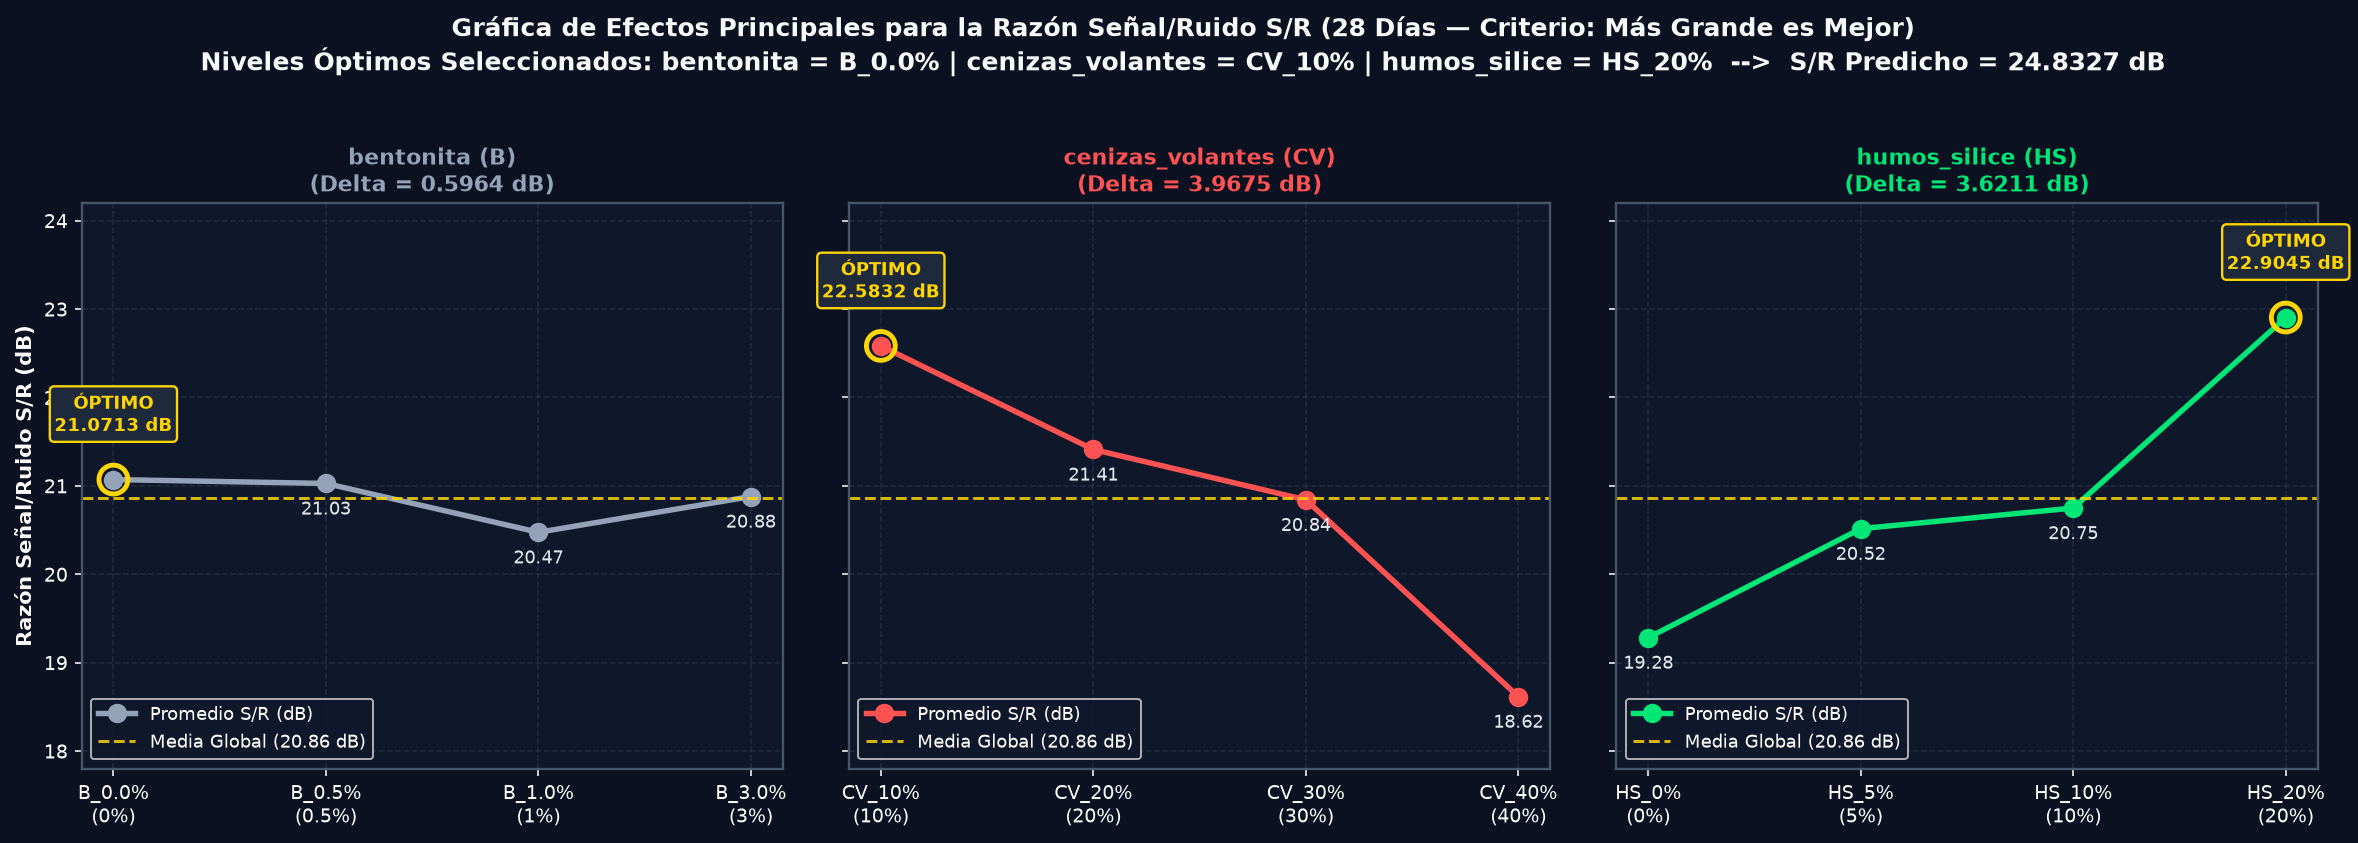

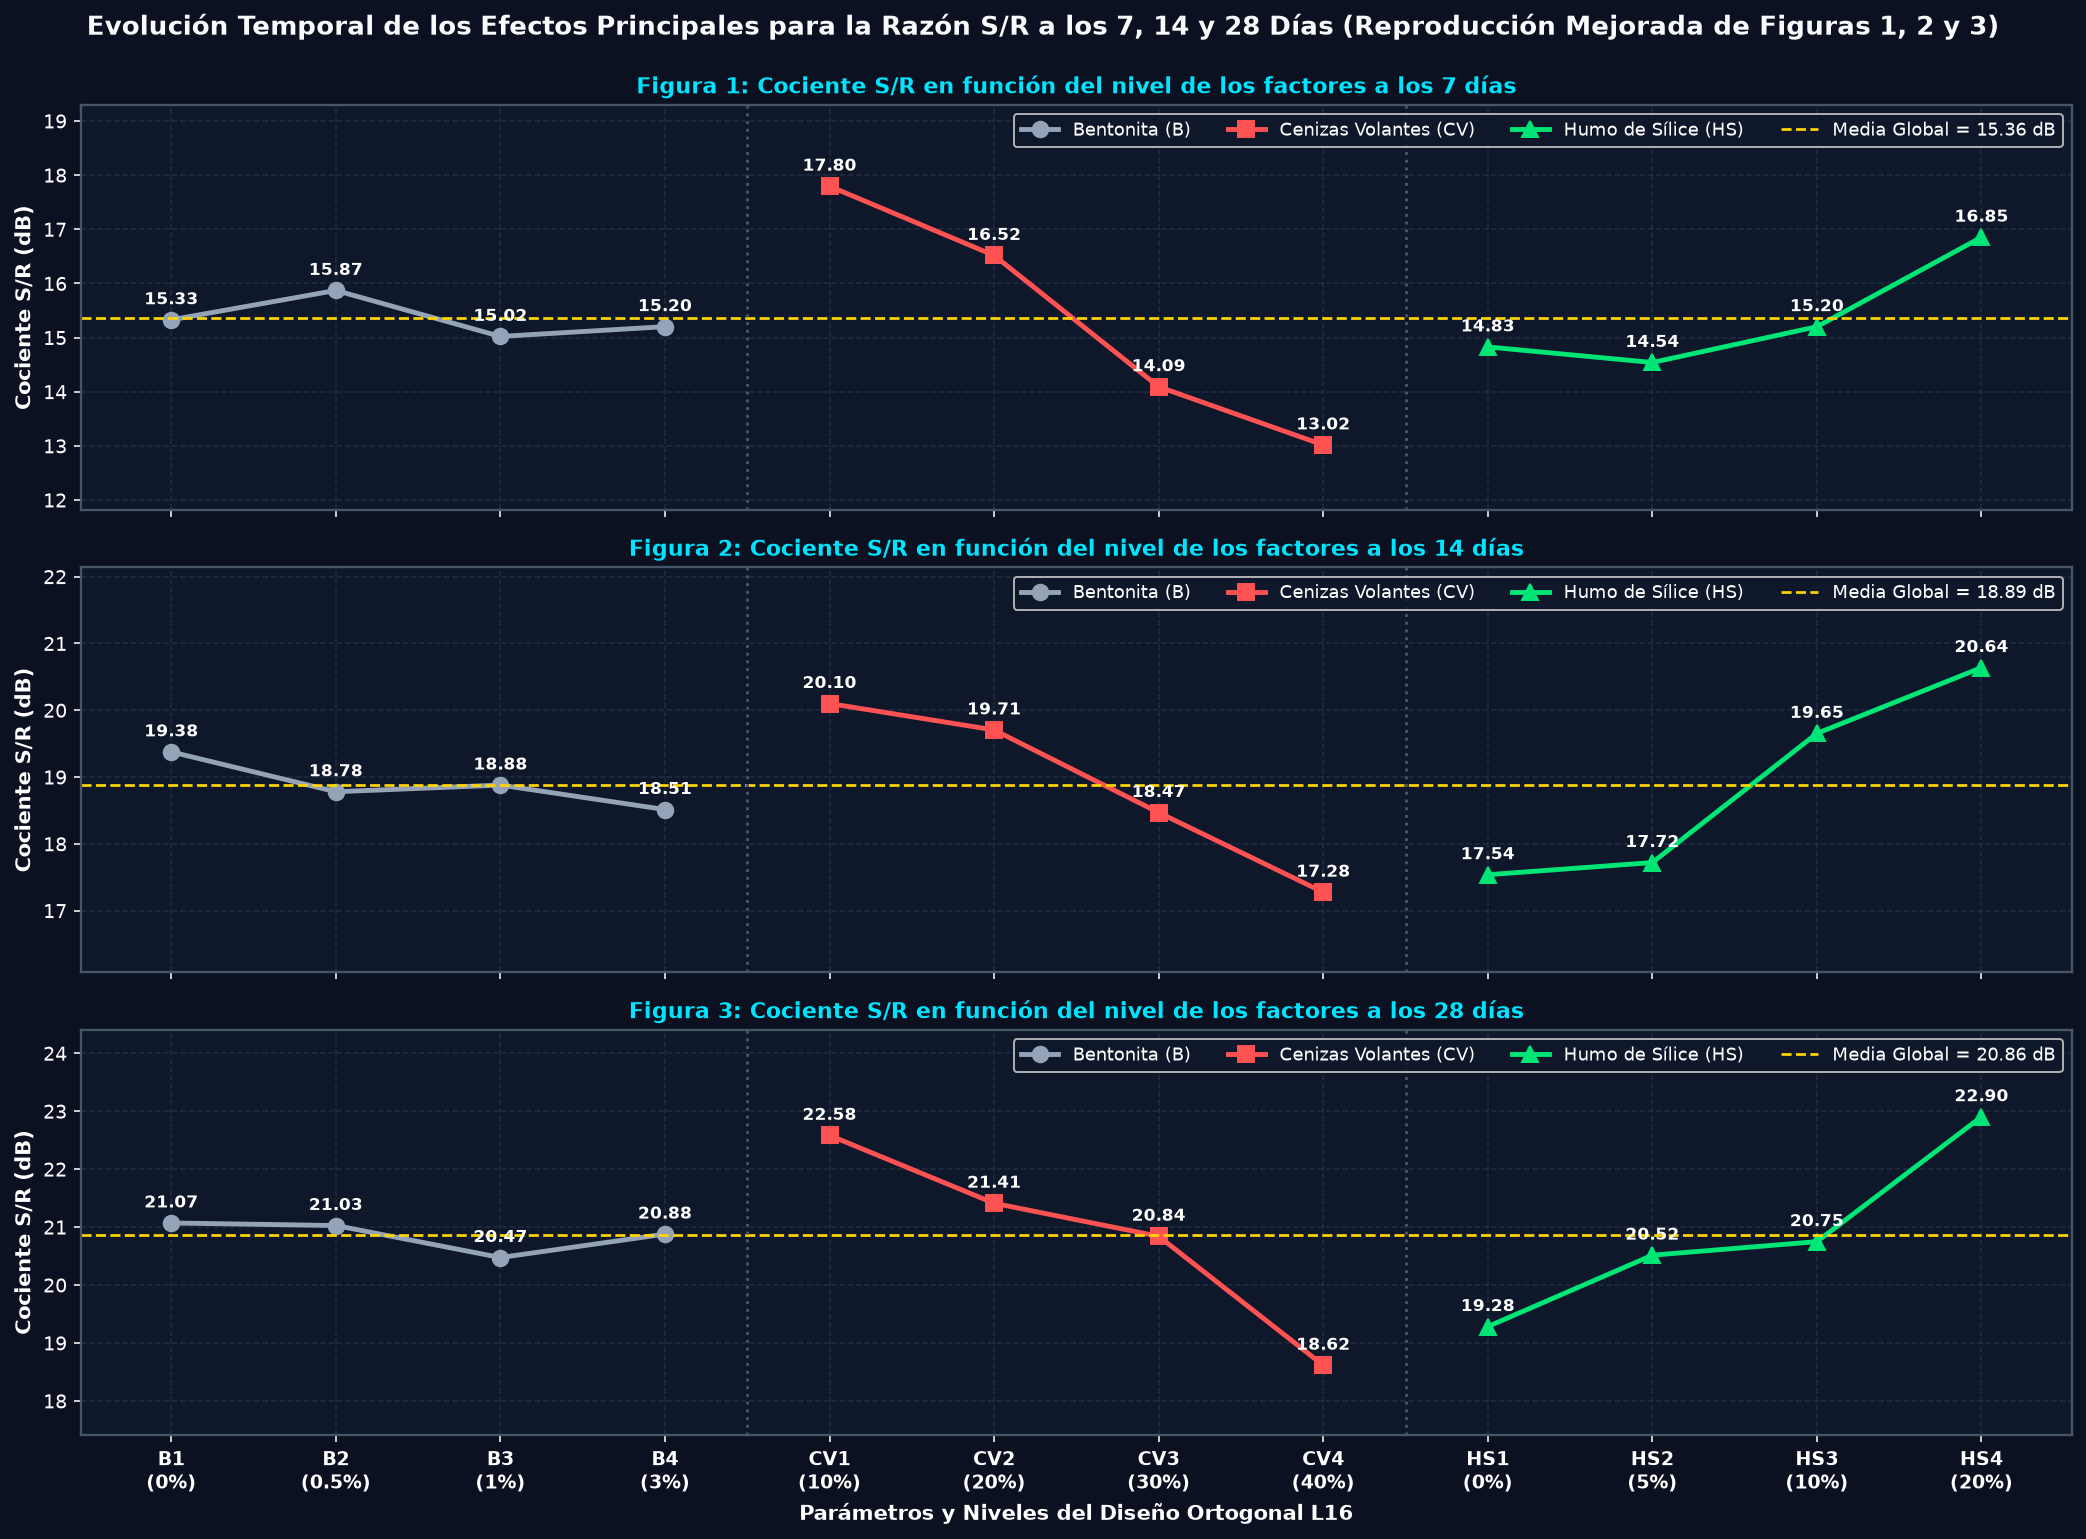

In [18]:
# ==============================================================================
# GRÁFICAS DE EFECTOS PRINCIPALES PARA LA RAZÓN SEÑAL/RUIDO (S/R)
# 1) DETALLE A 28 DÍAS (CON NIVELES ÓPTIMOS Y PREDICCIÓN 24.8327 dB)
# 2) PANEL MULTI-EDAD (7, 14 Y 28 DÍAS — FIGURAS 1, 2 Y 3 DEL ARTÍCULO)
# ==============================================================================

fig, axes = plt.subplots(1, 3, figsize=(17, 5.8), sharey=True)
fig.suptitle(
    'Gráfica de Efectos Principales para la Razón Señal/Ruido S/R (28 Días — Criterio: Más Grande es Mejor)\n'
    'Niveles Óptimos Seleccionados: bentonita = B_0.0% | cenizas_volantes = CV_10% | humos_silice = HS_20%  -->  S/R Predicho = 24.8327 dB',
    fontsize=13, fontweight='bold', color='#F8FAFC', y=1.03
)

factores_plot = [
    ('bentonita (B)', 'Nivel_B', ['B_0.0%\n(0%)', 'B_0.5%\n(0.5%)', 'B_1.0%\n(1%)', 'B_3.0%\n(3%)'], PALETTE['slate']),
    ('cenizas_volantes (CV)', 'Nivel_CV', ['CV_10%\n(10%)', 'CV_20%\n(20%)', 'CV_30%\n(30%)', 'CV_40%\n(40%)'], PALETTE['coral']),
    ('humos_silice (HS)', 'Nivel_HS', ['HS_0%\n(0%)', 'HS_5%\n(5%)', 'HS_10%\n(10%)', 'HS_20%\n(20%)'], PALETTE['emerald'])
]

grand_mean_sr28 = df_tabla3['SR_28d'].mean()

for ax, (f_title, f_col, x_labels, color) in zip(axes, factores_plot):
    means = [df_tabla3.loc[df_tabla3[f_col] == k, 'SR_28d'].mean() for k in [1, 2, 3, 4]]
    x_pos = np.arange(4)
    ax.plot(x_pos, means, marker='o', markersize=9, linewidth=2.8, color=color, label='Promedio S/R (dB)')
    ax.axhline(grand_mean_sr28, color=PALETTE['amber'], linestyle='--', linewidth=1.5, alpha=0.85, label=f'Media Global ({grand_mean_sr28:.2f} dB)')

    # Destacar el nivel óptimo
    opt_idx = int(np.argmax(means))
    ax.scatter([opt_idx], [means[opt_idx]], s=220, facecolors='none', edgecolors=PALETTE['amber'], linewidths=2.5, zorder=6)
    ax.annotate(
        f"ÓPTIMO\n{means[opt_idx]:.4f} dB",
        xy=(opt_idx, means[opt_idx]),
        xytext=(opt_idx, means[opt_idx] + 0.55),
        ha='center', fontsize=9.5, fontweight='bold', color=PALETTE['amber'],
        bbox=dict(boxstyle='round,pad=0.25', facecolor='#1E293B', edgecolor=PALETTE['amber'], lw=1.2)
    )

    for idx_pt, val in enumerate(means):
        if idx_pt != opt_idx:
            ax.annotate(f"{val:.2f}", (idx_pt, val), textcoords="offset points", xytext=(0, -16), ha='center', fontsize=9, color='#E2E8F0')

    delta_f = max(means) - min(means)
    ax.set_title(f"{f_title}\n(Delta = {delta_f:.4f} dB)", fontsize=11.5, color=color)
    ax.set_xticks(x_pos)
    ax.set_xticklabels(x_labels)
    ax.set_ylim(17.8, 24.2)
    ax.grid(True, linestyle='--', alpha=0.5)
    if ax == axes[0]:
        ax.set_ylabel('Razón Señal/Ruido S/R (dB)', fontsize=11)
    ax.legend(loc='lower left', framealpha=0.85)

plt.tight_layout()
plt.show()

# Panel comparativo de las Figuras 1, 2 y 3 del artículo (7, 14 y 28 días)
fig, axes = plt.subplots(3, 1, figsize=(15, 11), sharex=True)
fig.suptitle(
    'Evolución Temporal de los Efectos Principales para la Razón S/R a los 7, 14 y 28 Días (Reproducción Mejorada de Figuras 1, 2 y 3)',
    fontsize=13.5, fontweight='bold', color='#F8FAFC', y=0.995
)

x_labels_12 = ['B1\n(0%)', 'B2\n(0.5%)', 'B3\n(1%)', 'B4\n(3%)',
               'CV1\n(10%)', 'CV2\n(20%)', 'CV3\n(30%)', 'CV4\n(40%)',
               'HS1\n(0%)', 'HS2\n(5%)', 'HS3\n(10%)', 'HS4\n(20%)']

for ax, (sr_col, edad_lbl, fig_num) in zip(axes, [('SR_7d', '7 días', 'Figura 1'), ('SR_14d', '14 días', 'Figura 2'), ('SR_28d', '28 días', 'Figura 3')]):
    m_B = [df_tabla3.loc[df_tabla3['Nivel_B'] == k, sr_col].mean() for k in [1, 2, 3, 4]]
    m_CV = [df_tabla3.loc[df_tabla3['Nivel_CV'] == k, sr_col].mean() for k in [1, 2, 3, 4]]
    m_HS = [df_tabla3.loc[df_tabla3['Nivel_HS'] == k, sr_col].mean() for k in [1, 2, 3, 4]]
    g_mean = df_tabla3[sr_col].mean()

    ax.plot(range(0, 4), m_B, 'o-', color=PALETTE['slate'], lw=2.5, ms=8, label='Bentonita (B)')
    ax.plot(range(4, 8), m_CV, 's-', color=PALETTE['coral'], lw=2.5, ms=8, label='Cenizas Volantes (CV)')
    ax.plot(range(8, 12), m_HS, '^-', color=PALETTE['emerald'], lw=2.5, ms=8, label='Humo de Sílice (HS)')
    ax.axhline(g_mean, color=PALETTE['amber'], ls='--', lw=1.4, label=f'Media Global = {g_mean:.2f} dB')

    ax.axvline(3.5, color='#475569', ls=':', lw=1.5)
    ax.axvline(7.5, color='#475569', ls=':', lw=1.5)

    for i_x, val in enumerate(m_B + m_CV + m_HS):
        ax.annotate(f"{val:.2f}", (i_x, val), textcoords="offset points", xytext=(0, 8), ha='center', fontsize=8.5, fontweight='bold')

    ax.set_title(f"{fig_num}: Cociente S/R en función del nivel de los factores a los {edad_lbl}", fontsize=11.5, color=PALETTE['cyan'])
    ax.set_ylabel('Cociente S/R (dB)')
    ax.set_ylim(min(m_B + m_CV + m_HS) - 1.2, max(m_B + m_CV + m_HS) + 1.5)
    ax.legend(loc='upper right', ncol=4, framealpha=0.85)
    ax.grid(True, linestyle='--', alpha=0.5)

axes[-1].set_xticks(range(12))
axes[-1].set_xticklabels(x_labels_12, fontweight='bold')
axes[-1].set_xlabel('Parámetros y Niveles del Diseño Ortogonal L16', fontsize=11)
plt.tight_layout()
plt.show()

---
## SECCIÓN 4: Paso 2 de Taguchi — Análisis de la Media de la Respuesta ($\bar{Y}$), Desviación Estándar ($S$) y Gráfica de Efectos Principales para la Media

### 4.1 Necesidad del Análisis Conjunto de la Media ($\bar{Y}$) y la Variabilidad (Gutiérrez & De la Vara, págs. 309–312)
Como establecen Gutiérrez Pulido & De la Vara Salazar en el **Capítulo 9 (pág. 309)**, la optimización de un diseño robusto requiere obligatoriamente dos pasos:
1. Analizar el estadístico **Razón Señal/Ruido ($S/R$)** para determinar las condiciones que hacen al producto más robusto (insensible al ruido).
2. Analizar la **Media de la Respuesta ($\bar{Y}$)** mediante su tabla de respuesta, sus gráficas de efectos principales y su ANOVA:
   $$\bar{Y}_i = \frac{1}{n} \sum_{j=1}^{n} Y_{ij}, \quad S_i = \sqrt{\frac{1}{n-1}\sum_{j=1}^{n}\left(Y_{ij} - \bar{Y}_i\right)^2}, \quad i = 1, \dots, 16; \quad n = 3$$

Adicionalmente, el libro recomienda evaluar:
* El **diagrama de dispersión $(\bar{Y}_i, S_i)$** de Fowlkes & Creveling (pág. 309) para verificar si la media y la desviación estándar son independientes o presentan dependencia funcional.
* El estadístico general de variabilidad pura (Nominal Tipo II):
  $$S/R_{\text{N2}, i} = -10 \log_{10} \left(S_i^2\right)$$
  *(Nota técnica: en corridas donde las 3 probetas registran idéntica lectura hasta el centésimo de MPa, $S_i^2 = 0$, por lo que se regulariza con la resolución instrumental $\epsilon = 10^{-4}\text{ MPa}^2$ para evitar singularidades logarítmicas).*

In [19]:
# ==============================================================================
# CÁLCULO DE LA MEDIA (Y_BARRA), DESVIACIÓN ESTÁNDAR (S), CV(%) Y -10*LOG10(S^2)
# ==============================================================================

for edad, cols in [('7d', cols_7d), ('14d', cols_14d), ('28d', cols_28d)]:
    mat = df_tabla3[cols].to_numpy()
    df_tabla3[f'Media_{edad}'] = np.mean(mat, axis=1)
    df_tabla3[f'DE_{edad}'] = np.std(mat, axis=1, ddof=1)
    df_tabla3[f'CV_{edad}_%'] = (df_tabla3[f'DE_{edad}'] / df_tabla3[f'Media_{edad}']) * 100.0
    # Estadístico Tipo II del libro: -10 * log10(S^2), con regularización de precisión instrumental (1e-4) cuando S=0
    s2_reg = np.maximum(df_tabla3[f'DE_{edad}'].to_numpy() ** 2, 1e-4)
    df_tabla3[f'SR_Var_{edad}'] = -10.0 * np.log10(s2_reg)

resumen_estadistico = df_tabla3[[
    'Prueba', 'bentonita', 'cenizas_volantes', 'humos_silice',
    'Media_7d', 'DE_7d', 'SR_7d',
    'Media_14d', 'DE_14d', 'SR_14d',
    'Media_28d', 'DE_28d', 'SR_28d'
]]

print("================================================================================================================")
print(" RESUMEN DE ESTADÍSTICOS POR CORRIDA EXPERIMENTAL (MEDIA Ȳ, DESVIACIÓN ESTÁNDAR S Y RAZÓN S/R)")
print("================================================================================================================")
display(resumen_estadistico)

# Construcción de Tablas de Respuesta para la Media (Y_barra) en 7, 14 y 28 días
tabla_media_7d = build_response_table(df_tabla3, 'Media_7d')
tabla_media_14d = build_response_table(df_tabla3, 'Media_14d')
tabla_media_28d = build_response_table(df_tabla3, 'Media_28d')

print("\n================================================================================================================")
print(" TABLA DE RESPUESTA PARA LA MEDIA DE LA RESISTENCIA A COMPRESIÓN Ȳ (MPa) — 7 DÍAS")
print("================================================================================================================")
display(tabla_media_7d)

print("\n================================================================================================================")
print(" TABLA DE RESPUESTA PARA LA MEDIA DE LA RESISTENCIA A COMPRESIÓN Ȳ (MPa) — 14 DÍAS")
print("================================================================================================================")
display(tabla_media_14d)

print("\n================================================================================================================")
print(" TABLA DE RESPUESTA PARA LA MEDIA DE LA RESISTENCIA A COMPRESIÓN Ȳ (MPa) — 28 DÍAS")
print("================================================================================================================")
display(tabla_media_28d)

 RESUMEN DE ESTADÍSTICOS POR CORRIDA EXPERIMENTAL (MEDIA Ȳ, DESVIACIÓN ESTÁNDAR S Y RAZÓN S/R)


,Prueba,bentonita,cenizas_volantes,humos_silice,Media_7d,DE_7d,SR_7d,Media_14d,DE_14d,SR_14d,Media_28d,DE_28d,SR_28d
0,1,B_0.0%,CV_10%,HS_0%,8.0500,0.4795,18.0837,10.4067,0.1501,20.3444,13.6667,0.4400,22.7042
1,2,B_0.0%,CV_20%,HS_5%,6.0233,0.2540,15.5808,7.3833,0.2021,17.3584,10.4833,0.3066,20.4024
2,3,B_0.0%,CV_30%,HS_10%,4.3733,0.0635,12.8144,8.9400,0.1039,19.0256,9.1800,0.3504,19.2441
3,4,B_0.0%,CV_40%,HS_20%,5.5267,0.2219,14.8351,10.9833,0.6825,20.7795,12.5233,0.6120,21.9344
4,5,B_0.5%,CV_10%,HS_5%,7.2067,0.2540,17.1442,8.8700,0.3601,18.9444,12.6700,0.5756,22.0375
5,6,B_0.5%,CV_20%,HS_0%,6.3933,0.2201,16.1042,8.6267,0.4406,18.6943,9.7000,0.0000,19.7354
6,7,B_0.5%,CV_30%,HS_20%,6.9100,0.2598,16.7769,10.1400,0.4400,20.1044,15.1400,0.7484,23.5806
7,8,B_0.5%,CV_40%,HS_10%,4.7400,0.3966,13.4571,7.4067,0.3060,17.3781,8.6733,0.2540,18.7561
8,9,B_1.0%,CV_10%,HS_10%,7.5000,0.4400,17.4713,11.4433,0.4466,21.1579,12.6433,0.5081,22.0236
9,10,B_1.0%,CV_20%,HS_20%,7.3533,0.2540,17.3190,12.1833,0.0231,21.7153,13.4333,0.7753,22.5355



 TABLA DE RESPUESTA PARA LA MEDIA DE LA RESISTENCIA A COMPRESIÓN Ȳ (MPa) — 7 DÍAS


,Factor,Nivel 1,Nivel 2,Nivel 3,Nivel 4,Delta (Máx-Mín),Jerarquía (Rank),Nivel Óptimo,Valor Máx
0,bentonita (B),5.9933,6.3125,5.8667,6.0383,0.4458,3,B_0.5% (Nivel 2),6.3125
1,cenizas_volantes (CV),7.7892,6.7258,5.1633,4.5325,3.2567,1,CV_10% (Nivel 1),7.7892
2,humos_silice (HS),5.7450,5.4817,5.9367,7.0475,1.5658,2,HS_20% (Nivel 4),7.0475



 TABLA DE RESPUESTA PARA LA MEDIA DE LA RESISTENCIA A COMPRESIÓN Ȳ (MPa) — 14 DÍAS


,Factor,Nivel 1,Nivel 2,Nivel 3,Nivel 4,Delta (Máx-Mín),Jerarquía (Rank),Nivel Óptimo,Valor Máx
0,bentonita (B),9.4283,8.7608,9.1842,8.7375,0.6908,3,B_0.0% (Nivel 1),9.4283
1,cenizas_volantes (CV),10.1700,9.8708,8.4883,7.5817,2.5883,2,CV_10% (Nivel 1),10.1700
2,humos_silice (HS),7.7717,7.7525,9.7700,10.8167,3.0642,1,HS_20% (Nivel 4),10.8167



 TABLA DE RESPUESTA PARA LA MEDIA DE LA RESISTENCIA A COMPRESIÓN Ȳ (MPa) — 28 DÍAS


,Factor,Nivel 1,Nivel 2,Nivel 3,Nivel 4,Delta (Máx-Mín),Jerarquía (Rank),Nivel Óptimo,Valor Máx
0,bentonita (B),11.4633,11.5458,10.8183,11.7683,0.9500,3,B_3.0% (Nivel 4),11.7683
1,cenizas_volantes (CV),13.5292,11.9467,11.2850,8.8350,4.6942,1,CV_10% (Nivel 1),13.5292
2,humos_silice (HS),9.6050,10.7658,11.1667,14.0583,4.4533,2,HS_20% (Nivel 4),14.0583


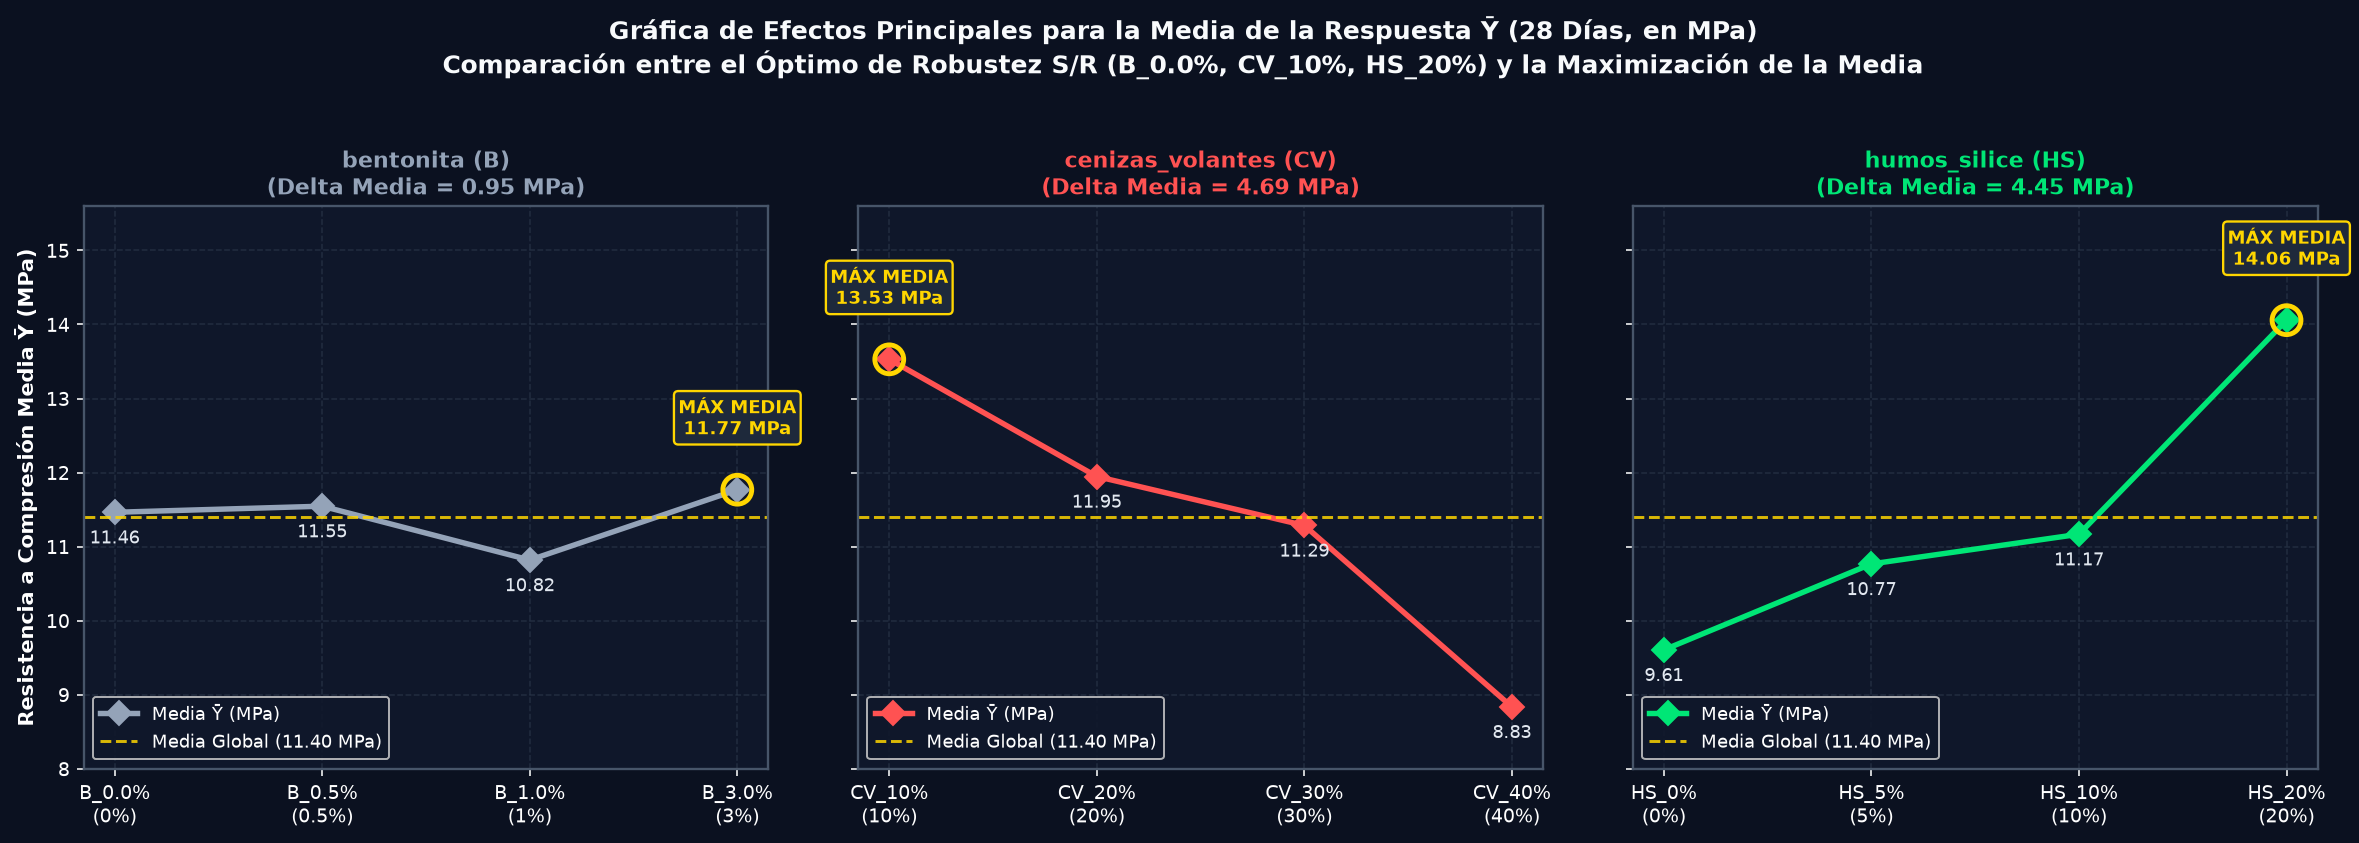

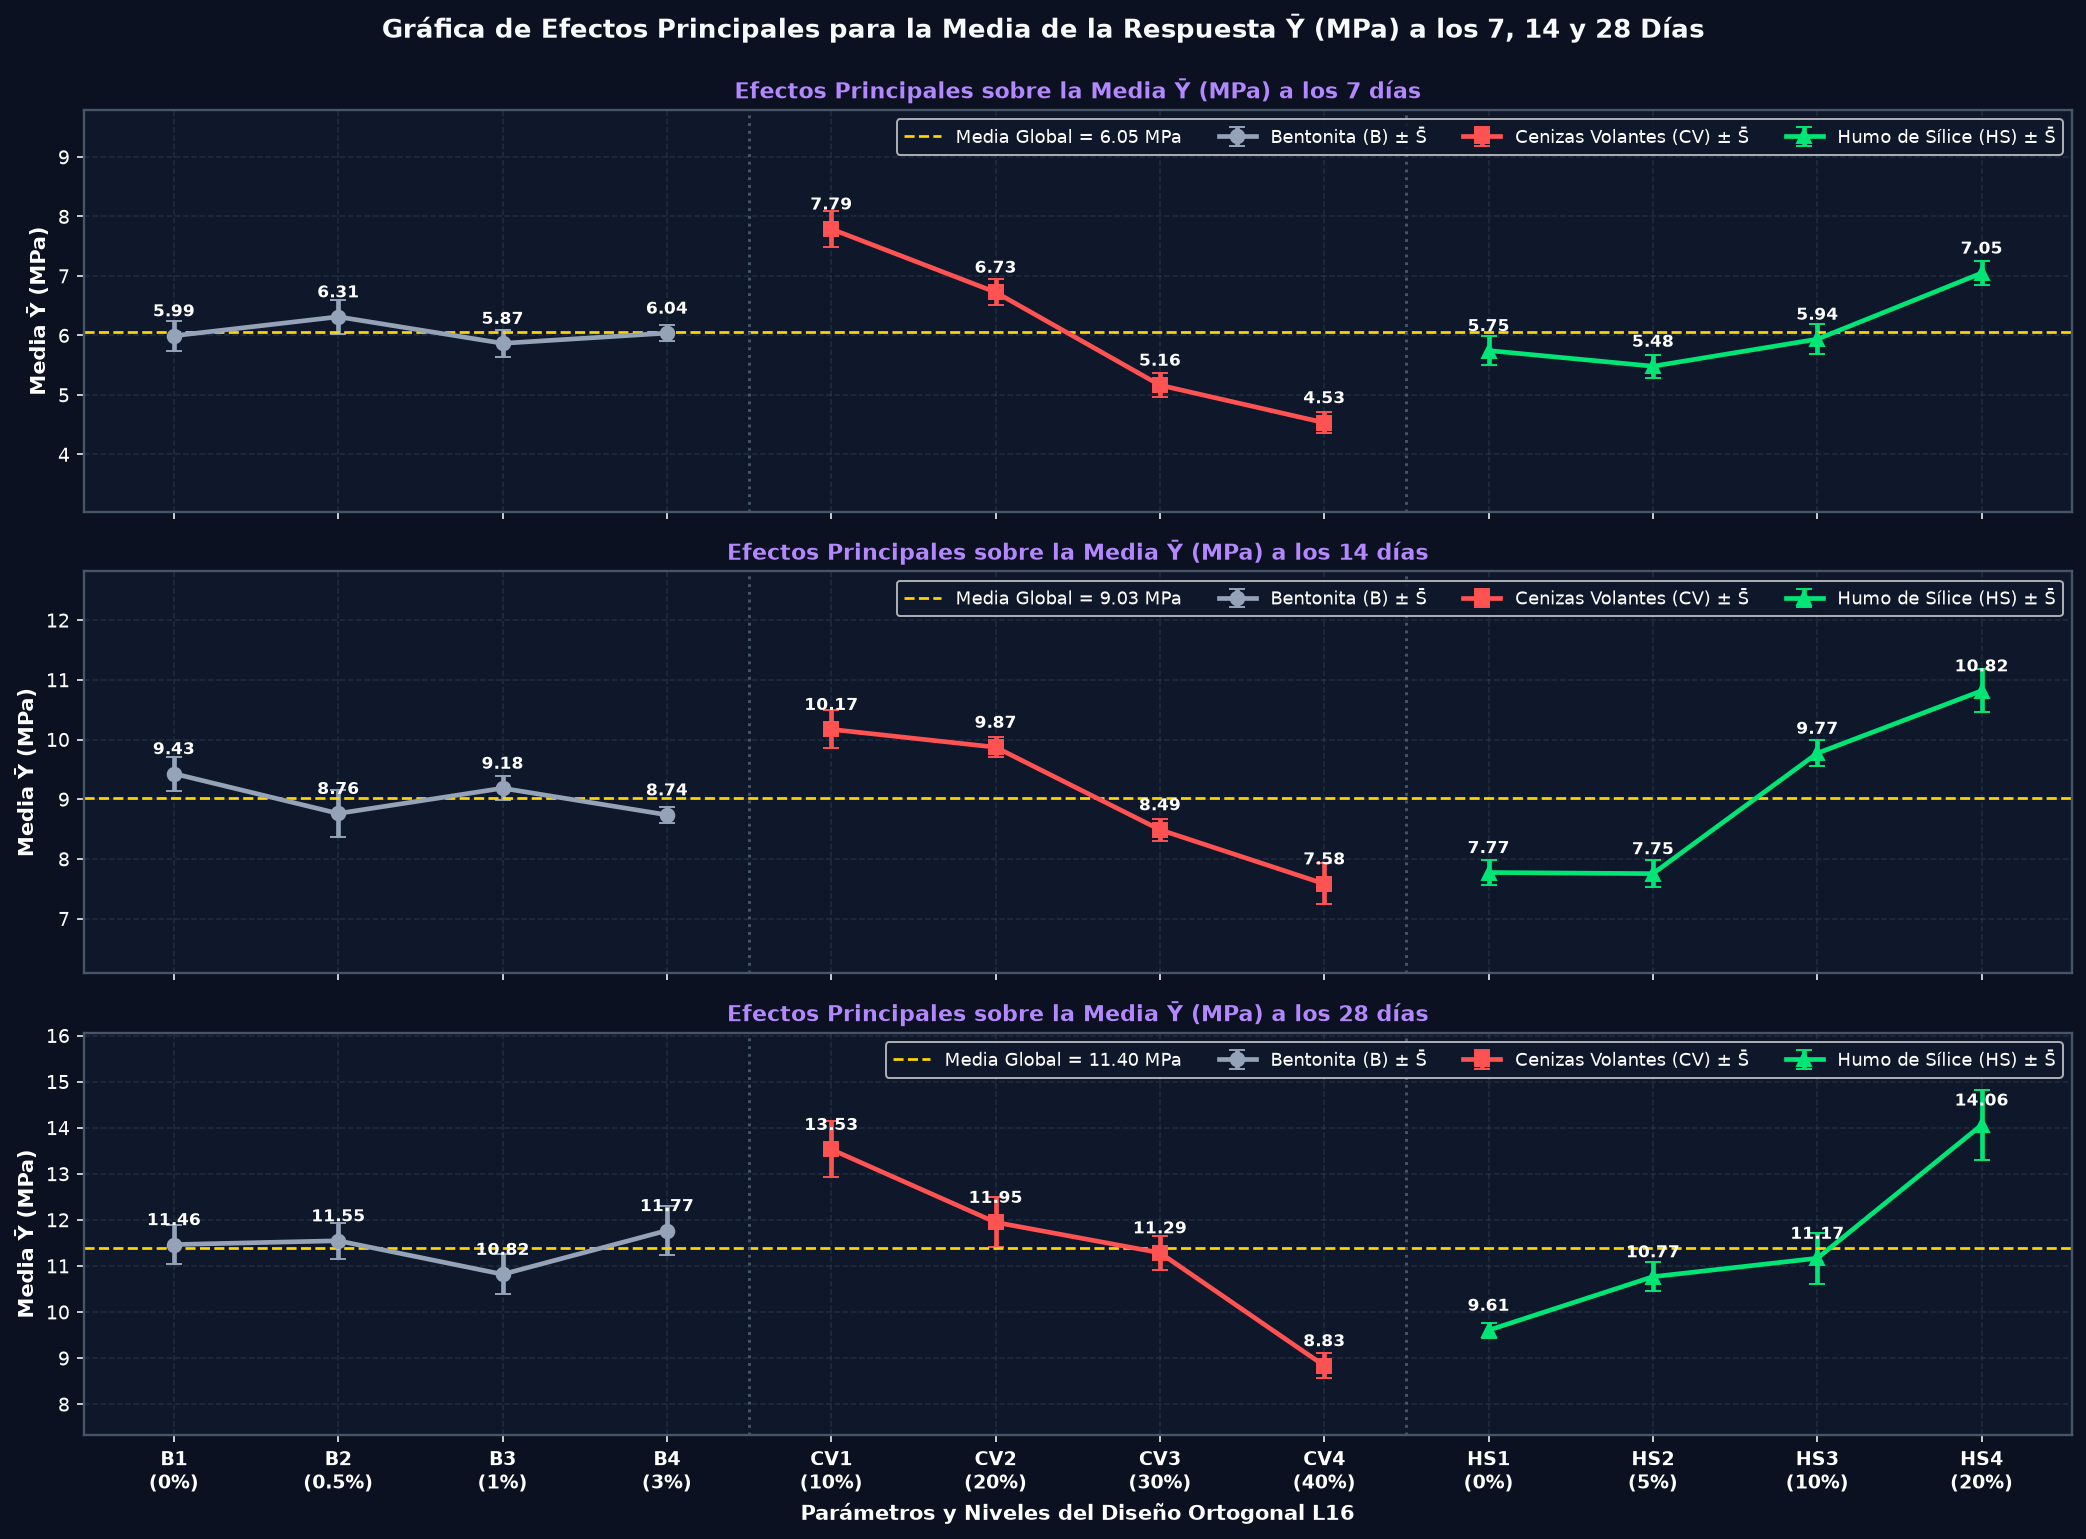

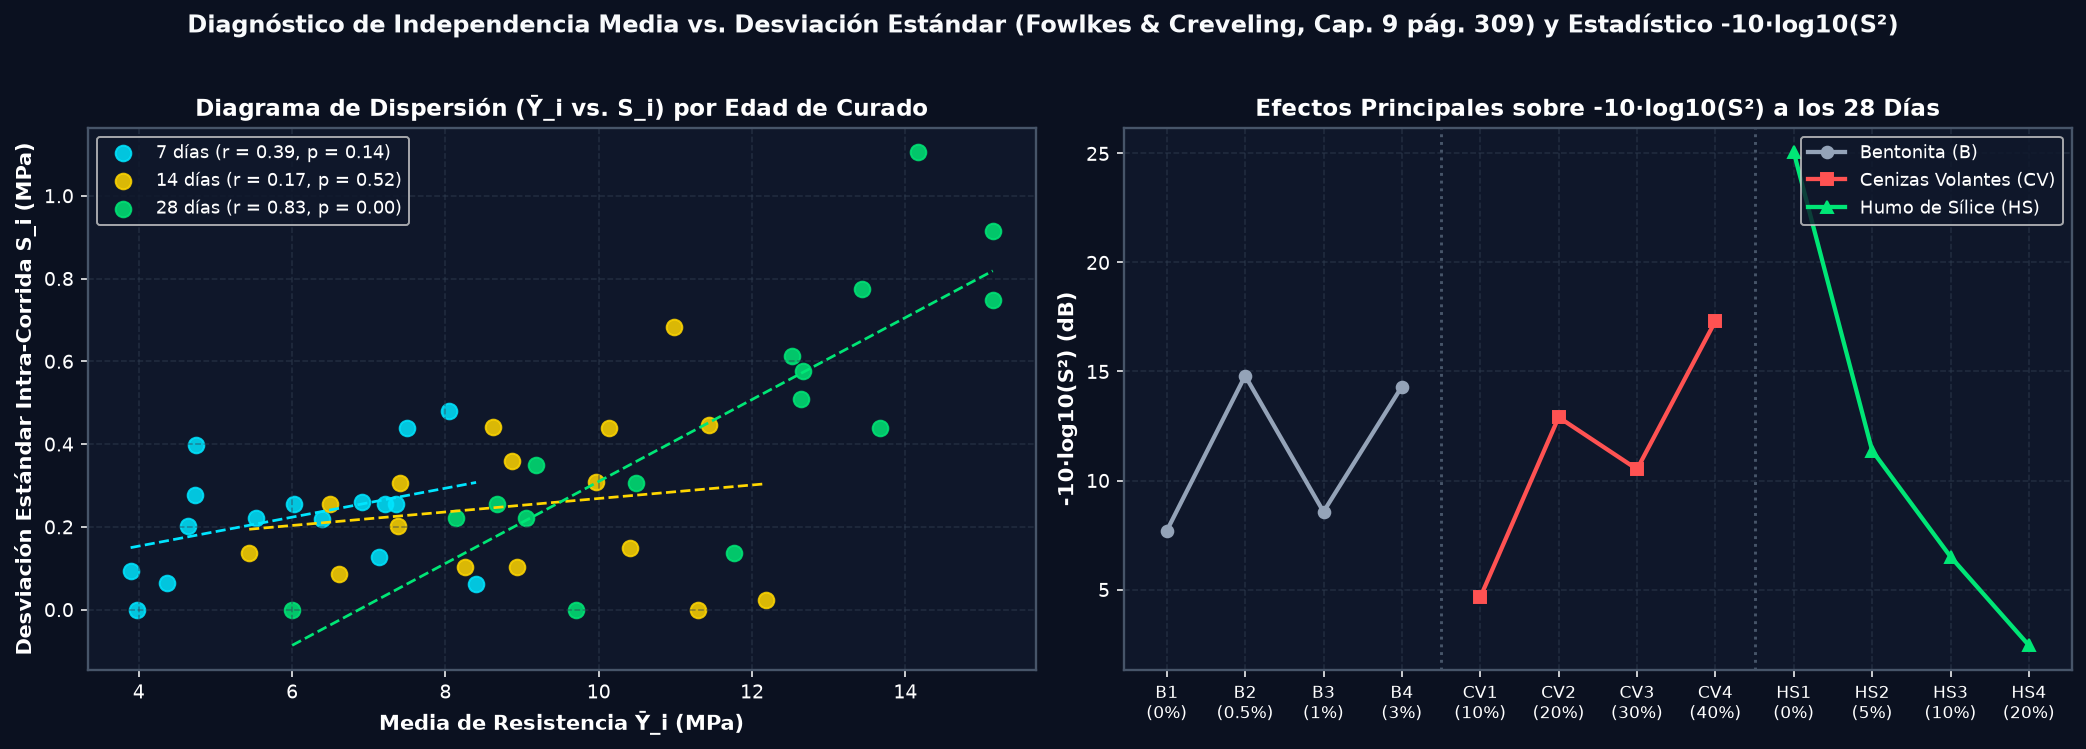

In [20]:
# ==============================================================================
# GRÁFICAS DE EFECTOS PRINCIPALES PARA LA MEDIA DE LA RESPUESTA (Y_BARRA EN MPa)
# Y DIAGNÓSTICO DE FOWLKES-CREVELING (MEDIA VS DESVIACIÓN ESTÁNDAR)
# ==============================================================================

# 1. Gráfica de Efectos Principales para la Media a 28 días
fig, axes = plt.subplots(1, 3, figsize=(17, 5.8), sharey=True)
fig.suptitle(
    'Gráfica de Efectos Principales para la Media de la Respuesta Ȳ (28 Días, en MPa)\n'
    'Comparación entre el Óptimo de Robustez S/R (B_0.0%, CV_10%, HS_20%) y la Maximización de la Media',
    fontsize=13, fontweight='bold', color='#F8FAFC', y=1.03
)

grand_mean_y28 = df_tabla3['Media_28d'].mean()

for ax, (f_title, f_col, x_labels, color) in zip(axes, factores_plot):
    means = [df_tabla3.loc[df_tabla3[f_col] == k, 'Media_28d'].mean() for k in [1, 2, 3, 4]]
    x_pos = np.arange(4)
    ax.plot(x_pos, means, marker='D', markersize=8.5, linewidth=2.8, color=color, label='Media Ȳ (MPa)')
    ax.axhline(grand_mean_y28, color=PALETTE['amber'], linestyle='--', linewidth=1.5, alpha=0.85, label=f'Media Global ({grand_mean_y28:.2f} MPa)')

    opt_idx = int(np.argmax(means))
    ax.scatter([opt_idx], [means[opt_idx]], s=220, facecolors='none', edgecolors=PALETTE['amber'], linewidths=2.5, zorder=6)
    ax.annotate(
        f"MÁX MEDIA\n{means[opt_idx]:.2f} MPa",
        xy=(opt_idx, means[opt_idx]),
        xytext=(opt_idx, means[opt_idx] + 0.75),
        ha='center', fontsize=9, fontweight='bold', color=PALETTE['amber'],
        bbox=dict(boxstyle='round,pad=0.25', facecolor='#1E293B', edgecolor=PALETTE['amber'], lw=1.2)
    )

    for idx_pt, val in enumerate(means):
        if idx_pt != opt_idx:
            ax.annotate(f"{val:.2f}", (idx_pt, val), textcoords="offset points", xytext=(0, -16), ha='center', fontsize=9, color='#E2E8F0')

    delta_f = max(means) - min(means)
    ax.set_title(f"{f_title}\n(Delta Media = {delta_f:.2f} MPa)", fontsize=11.5, color=color)
    ax.set_xticks(x_pos)
    ax.set_xticklabels(x_labels)
    ax.set_ylim(8.0, 15.6)
    ax.grid(True, linestyle='--', alpha=0.5)
    if ax == axes[0]:
        ax.set_ylabel('Resistencia a Compresión Media Ȳ (MPa)', fontsize=11)
    ax.legend(loc='lower left', framealpha=0.85)

plt.tight_layout()
plt.show()

# 2. Panel Multi-Edad de Efectos Principales para la Media (7, 14 y 28 días) con barras de dispersión intra-corrida
fig, axes = plt.subplots(3, 1, figsize=(15, 11), sharex=True)
fig.suptitle(
    'Gráfica de Efectos Principales para la Media de la Respuesta Ȳ (MPa) a los 7, 14 y 28 Días',
    fontsize=13.5, fontweight='bold', color='#F8FAFC', y=0.995
)

for ax, (m_col, de_col, edad_lbl) in zip(axes, [('Media_7d', 'DE_7d', '7 días'), ('Media_14d', 'DE_14d', '14 días'), ('Media_28d', 'DE_28d', '28 días')]):
    m_B = [df_tabla3.loc[df_tabla3['Nivel_B'] == k, m_col].mean() for k in [1, 2, 3, 4]]
    m_CV = [df_tabla3.loc[df_tabla3['Nivel_CV'] == k, m_col].mean() for k in [1, 2, 3, 4]]
    m_HS = [df_tabla3.loc[df_tabla3['Nivel_HS'] == k, m_col].mean() for k in [1, 2, 3, 4]]

    s_B = [df_tabla3.loc[df_tabla3['Nivel_B'] == k, de_col].mean() for k in [1, 2, 3, 4]]
    s_CV = [df_tabla3.loc[df_tabla3['Nivel_CV'] == k, de_col].mean() for k in [1, 2, 3, 4]]
    s_HS = [df_tabla3.loc[df_tabla3['Nivel_HS'] == k, de_col].mean() for k in [1, 2, 3, 4]]
    g_mean = df_tabla3[m_col].mean()

    ax.errorbar(range(0, 4), m_B, yerr=s_B, fmt='o-', color=PALETTE['slate'], lw=2.4, ms=7, capsize=4, label='Bentonita (B) ± S̄')
    ax.errorbar(range(4, 8), m_CV, yerr=s_CV, fmt='s-', color=PALETTE['coral'], lw=2.4, ms=7, capsize=4, label='Cenizas Volantes (CV) ± S̄')
    ax.errorbar(range(8, 12), m_HS, yerr=s_HS, fmt='^-', color=PALETTE['emerald'], lw=2.4, ms=7, capsize=4, label='Humo de Sílice (HS) ± S̄')
    ax.axhline(g_mean, color=PALETTE['amber'], ls='--', lw=1.4, label=f'Media Global = {g_mean:.2f} MPa')

    ax.axvline(3.5, color='#475569', ls=':', lw=1.5)
    ax.axvline(7.5, color='#475569', ls=':', lw=1.5)

    for i_x, val in enumerate(m_B + m_CV + m_HS):
        ax.annotate(f"{val:.2f}", (i_x, val), textcoords="offset points", xytext=(0, 10), ha='center', fontsize=8.5, fontweight='bold')

    ax.set_title(f"Efectos Principales sobre la Media Ȳ (MPa) a los {edad_lbl}", fontsize=11.5, color=PALETTE['purple'])
    ax.set_ylabel('Media Ȳ (MPa)')
    ax.set_ylim(min(m_B + m_CV + m_HS) - 1.5, max(m_B + m_CV + m_HS) + 2.0)
    ax.legend(loc='upper right', ncol=4, framealpha=0.85)
    ax.grid(True, linestyle='--', alpha=0.5)

axes[-1].set_xticks(range(12))
axes[-1].set_xticklabels(x_labels_12, fontweight='bold')
axes[-1].set_xlabel('Parámetros y Niveles del Diseño Ortogonal L16', fontsize=11)
plt.tight_layout()
plt.show()

# 3. Diagrama de Dispersión (Y_barra vs S) de Fowlkes & Creveling y Efectos para -10*log10(S^2)
fig, axes = plt.subplots(1, 2, figsize=(15, 5.2))
fig.suptitle(
    'Diagnóstico de Independencia Media vs. Desviación Estándar (Fowlkes & Creveling, Cap. 9 pág. 309) y Estadístico -10·log10(S²)',
    fontsize=12.5, fontweight='bold', color='#F8FAFC', y=1.02
)

for edad, m_col, s_col, col_c in [('7 días', 'Media_7d', 'DE_7d', PALETTE['cyan']),
                                  ('14 días', 'Media_14d', 'DE_14d', PALETTE['amber']),
                                  ('28 días', 'Media_28d', 'DE_28d', PALETTE['emerald'])]:
    r_corr, p_corr = stats.pearsonr(df_tabla3[m_col], df_tabla3[s_col])
    axes[0].scatter(df_tabla3[m_col], df_tabla3[s_col], s=65, alpha=0.85, color=col_c, label=f"{edad} (r = {r_corr:.2f}, p = {p_corr:.2f})")
    z_fit = np.polyfit(df_tabla3[m_col], df_tabla3[s_col], 1)
    x_line = np.linspace(df_tabla3[m_col].min(), df_tabla3[m_col].max(), 50)
    axes[0].plot(x_line, np.polyval(z_fit, x_line), ls='--', lw=1.4, color=col_c)

axes[0].set_title('Diagrama de Dispersión (Ȳ_i vs. S_i) por Edad de Curado')
axes[0].set_xlabel('Media de Resistencia Ȳ_i (MPa)')
axes[0].set_ylabel('Desviación Estándar Intra-Corrida S_i (MPa)')
axes[0].legend(loc='upper left')
axes[0].grid(True, ls='--', alpha=0.5)

# Efectos sobre -10*log10(S^2) a 28 días
v_B = [df_tabla3.loc[df_tabla3['Nivel_B'] == k, 'SR_Var_28d'].mean() for k in [1, 2, 3, 4]]
v_CV = [df_tabla3.loc[df_tabla3['Nivel_CV'] == k, 'SR_Var_28d'].mean() for k in [1, 2, 3, 4]]
v_HS = [df_tabla3.loc[df_tabla3['Nivel_HS'] == k, 'SR_Var_28d'].mean() for k in [1, 2, 3, 4]]
axes[1].plot(range(0, 4), v_B, 'o-', color=PALETTE['slate'], lw=2.2, label='Bentonita (B)')
axes[1].plot(range(4, 8), v_CV, 's-', color=PALETTE['coral'], lw=2.2, label='Cenizas Volantes (CV)')
axes[1].plot(range(8, 12), v_HS, '^-', color=PALETTE['emerald'], lw=2.2, label='Humo de Sílice (HS)')
axes[1].axvline(3.5, color='#475569', ls=':')
axes[1].axvline(7.5, color='#475569', ls=':')
axes[1].set_xticks(range(12))
axes[1].set_xticklabels(x_labels_12, fontsize=8.5)
axes[1].set_title('Efectos Principales sobre -10·log10(S²) a los 28 Días')
axes[1].set_ylabel('-10·log10(S²) (dB)')
axes[1].legend(loc='upper right')
axes[1].grid(True, ls='--', alpha=0.5)

plt.tight_layout()
plt.show()

---
## SECCIÓN 5: Análisis de Varianza (ANOVA), Reconstrucción de la Tabla 7 y Mejor ANOVA (*Pooling*)

### 5.1 Fórmulas de Descomposición de Sumas de Cuadrados en el Arreglo Ortogonal $L_{16} (4^3)$
Sea $z_i$ la respuesta analizada en la corrida $i \in \{1, \dots, 16\}$ (ya sea la razón $S/R_i$ o la media $\bar{Y}_i$), con media global $\bar{z} = \frac{1}{16}\sum_{i=1}^{16} z_i$:

1. **Suma de Cuadrados Total ($SC_{\text{Total}}$, con $GL_{\text{Total}} = N - 1 = 15$):**
   $$SC_{\text{Total}} = \sum_{i=1}^{16} \left(z_i - \bar{z}\right)^2$$

2. **Suma de Cuadrados de cada Factor $F \in \{B, CV, HS\}$ (con $GL_F = 4 - 1 = 3$):**
   $$SC_F = \sum_{k=1}^{4} 4 \left(\bar{z}_{F, k} - \bar{z}\right)^2$$

3. **Suma de Cuadrados del Error Residual ($SC_{\text{Error}}$, con $GL_{\text{Error}} = 15 - (3 + 3 + 3) = 6$):**
   $$SC_{\text{Error}} = SC_{\text{Total}} - \left(SC_B + SC_{CV} + SC_{HS}\right)$$

4. **Cuadrados Medios (Varianza $V_F$), Razón $F_0$, Valor-$p$ y Porcentaje de Contribución $P(\%)$:**
   $$V_F = CM_F = \frac{SC_F}{GL_F}, \quad V_e = CM_{\text{Error}} = \frac{SC_{\text{Error}}}{GL_{\text{Error}}}, \quad F_0 = \frac{V_F}{V_e} \sim F_{(3, GL_{\text{Error}})}, \quad P_F(\%) = \frac{SC_F}{SC_{\text{Total}}} \times 100\%$$

### 5.2 Procedimiento del "Mejor ANOVA" mediante Colapsación (*Pooling*) (Gutiérrez & De la Vara, Tabla 9.3)
En el Capítulo 9 del libro de referencia (pág. 311, Tabla 9.3), cuando un factor tiene un efecto nulo o despreciable (como `bentonita`, cuya contribución es $P \le 2.5\%$ y $F_0 < 0.75$ en todas las edades), mantenerlo en el modelo desperdicia $3$ grados de libertad y reduce la potencia estadística del ANOVA. Al **agrupar (*pool*) la Bentonita al término de error**:
$$SC_{\text{Error (Pooled)}} = SC_{\text{Error}} + SC_B, \quad GL_{\text{Error (Pooled)}} = 6 + 3 = 9$$
la estimación de la varianza del error $V_{e\text{ (Pooled)}}$ gana precisión y permite confirmar con rigor inferencial ($\alpha = 0.05$) la significancia estadística de `cenizas_volantes` y `humos_silice`.

In [21]:
# ==============================================================================
# CÁLCULO DEL ANOVA COMPLETO (TABLA 7 RECONSTRUIDA) Y MEJOR ANOVA (POOLING)
# TANTO PARA LA RAZÓN S/R COMO PARA LA MEDIA DE LA RESPUESTA (Y_BARRA)
# ==============================================================================

def compute_taguchi_anova(df: pd.DataFrame, response_col: str, pool_bentonita: bool = False) -> tuple[pd.DataFrame, dict]:
    z = df[response_col].to_numpy()
    grand_mean = float(np.mean(z))
    ss_total = float(np.sum((z - grand_mean) ** 2))

    factores = [
        ('bentonita (B)', 'Nivel_B'),
        ('cenizas_volantes (CV)', 'Nivel_CV'),
        ('humos_silice (HS)', 'Nivel_HS')
    ]

    ss_dict = {}
    for f_name, f_col in factores:
        means_k = np.array([df.loc[df[f_col] == k, response_col].mean() for k in [1, 2, 3, 4]])
        ss_dict[f_name] = float(4.0 * np.sum((means_k - grand_mean) ** 2))

    ss_error_raw = ss_total - sum(ss_dict.values())

    if not pool_bentonita:
        gl_err = 6
        ss_err = ss_error_raw
        active_factors = factores
    else:
        gl_err = 9
        ss_err = ss_error_raw + ss_dict['bentonita (B)']
        active_factors = factores[1:]  # Solo CV y HS activos; B agrupado al error

    v_err = ss_err / gl_err
    rows = []

    for f_name, _ in active_factors:
        ss_f = ss_dict[f_name]
        gl_f = 3
        v_f = ss_f / gl_f
        f_val = v_f / v_err
        p_val = float(1.0 - stats.f.cdf(f_val, gl_f, gl_err))
        p_pct = (ss_f / ss_total) * 100.0
        rows.append({
            'Fuente de Variación': f_name,
            'GL': gl_f,
            'SC (SS)': ss_f,
            'Varianza V (CM)': v_f,
            'Razón F': f_val,
            'Valor-p': p_val,
            'Contribución P (%)': p_pct,
            'Significancia (α=0.05)': 'Significativo **' if p_val < 0.05 else ('Marginal *' if p_val < 0.10 else 'No significativo')
        })

    rows.append({
        'Fuente de Variación': 'Error Residual (Pooled B+Error)' if pool_bentonita else 'Error Residual (Descon.)',
        'GL': gl_err,
        'SC (SS)': ss_err,
        'Varianza V (CM)': v_err,
        'Razón F': np.nan,
        'Valor-p': np.nan,
        'Contribución P (%)': (ss_err / ss_total) * 100.0,
        'Significancia (α=0.05)': ''
    })

    rows.append({
        'Fuente de Variación': 'Total',
        'GL': 15,
        'SC (SS)': ss_total,
        'Varianza V (CM)': ss_total / 15.0,
        'Razón F': np.nan,
        'Valor-p': np.nan,
        'Contribución P (%)': 100.0,
        'Significancia (α=0.05)': ''
    })

    ss_model = sum(ss_dict[f_name] for f_name, _ in active_factors)
    r2 = (ss_model / ss_total) * 100.0
    r2_adj = (1.0 - (v_err / (ss_total / 15.0))) * 100.0

    metrics = {'R2': r2, 'R2_adj': r2_adj, 'V_e': v_err, 'GL_e': gl_err, 'SS_Total': ss_total}
    return pd.DataFrame(rows), metrics

for edad, sr_col, m_col in [('7 DÍAS', 'SR_7d', 'Media_7d'), ('14 DÍAS', 'SR_14d', 'Media_14d'), ('28 DÍAS', 'SR_28d', 'Media_28d')]:
    print("================================================================================================================")
    print(f" RESULTADOS DEL ANÁLISIS DE LA VARIANZA (ANOVA) — EDAD: {edad}")
    print("================================================================================================================")

    df_anova_sr, met_sr = compute_taguchi_anova(df_tabla3, sr_col, pool_bentonita=False)
    print(f"\n[1] ANOVA Completo para la Razón S/R ({edad}) — Reconstrucción Exacta de la Tabla 7 (R² = {met_sr['R2']:.2f}%, R²_adj = {met_sr['R2_adj']:.2f}%):")
    display(df_anova_sr)

    df_pool_sr, met_psr = compute_taguchi_anova(df_tabla3, sr_col, pool_bentonita=True)
    print(f"[2] Mejor ANOVA (con Pooling de Bentonita, GL_E = 9) para la Razón S/R ({edad}) (R² = {met_psr['R2']:.2f}%, R²_adj = {met_psr['R2_adj']:.2f}%):")
    display(df_pool_sr)

    df_anova_m, met_m = compute_taguchi_anova(df_tabla3, m_col, pool_bentonita=False)
    df_pool_m, met_pm = compute_taguchi_anova(df_tabla3, m_col, pool_bentonita=True)
    print(f"[3] Mejor ANOVA (con Pooling de Bentonita, GL_E = 9) para la Media Ȳ en MPa ({edad}) (R² = {met_pm['R2']:.2f}%, R²_adj = {met_pm['R2_adj']:.2f}%):")
    display(df_pool_m)

 RESULTADOS DEL ANÁLISIS DE LA VARIANZA (ANOVA) — EDAD: 7 DÍAS

[1] ANOVA Completo para la Razón S/R (7 DÍAS) — Reconstrucción Exacta de la Tabla 7 (R² = 94.09%, R²_adj = 85.23%):


,Fuente de Variación,GL,SC (SS),Varianza V (CM),Razón F,Valor-p,Contribución P (%),Significancia (α=0.05)
0,bentonita (B),3,1.6044,0.5348,0.7103,0.5803,2.0989,No significativo
1,cenizas_volantes (CV),3,57.4658,19.1553,25.4419,0.0008,75.1776,Significativo **
2,humos_silice (HS),3,12.8524,4.2841,5.6902,0.0345,16.8137,Significativo **
3,Error Residual (Descon.),6,4.5174,0.7529,NaN,NaN,5.9097,
4,Total,15,76.4400,5.0960,NaN,NaN,100.0000,


[2] Mejor ANOVA (con Pooling de Bentonita, GL_E = 9) para la Razón S/R (7 DÍAS) (R² = 91.99%, R²_adj = 86.65%):


,Fuente de Variación,GL,SC (SS),Varianza V (CM),Razón F,Valor-p,Contribución P (%),Significancia (α=0.05)
0,cenizas_volantes (CV),3,57.4658,19.1553,28.1612,6.6181e-05,75.1776,Significativo **
1,humos_silice (HS),3,12.8524,4.2841,6.2984,1.3652e-02,16.8137,Significativo **
2,Error Residual (Pooled B+Error),9,6.1218,0.6802,NaN,NaN,8.0086,
3,Total,15,76.4400,5.0960,NaN,NaN,100.0000,


[3] Mejor ANOVA (con Pooling de Bentonita, GL_E = 9) para la Media Ȳ en MPa (7 DÍAS) (R² = 93.49%, R²_adj = 89.16%):


,Fuente de Variación,GL,SC (SS),Varianza V (CM),Razón F,Valor-p,Contribución P (%),Significancia (α=0.05)
0,cenizas_volantes (CV),3,26.2816,8.7605,35.4369,2.5949e-05,76.8424,Significativo **
1,humos_silice (HS),3,5.6954,1.8985,7.6794,7.4902e-03,16.6523,Significativo **
2,Error Residual (Pooled B+Error),9,2.2249,0.2472,NaN,NaN,6.5053,
3,Total,15,34.2020,2.2801,NaN,NaN,100.0000,


... (8 outputs left out)

[2] Mejor ANOVA (con Pooling de Bentonita, GL_E = 9) para la Razón S/R (28 DÍAS) (R² = 79.31%, R²_adj = 65.52%):


,Fuente de Variación,GL,SC (SS),Varianza V (CM),Razón F,Valor-p,Contribución P (%),Significancia (α=0.05)
0,cenizas_volantes (CV),3,33.2436,11.0812,6.3268,0.0135,43.6305,Significativo **
1,humos_silice (HS),3,27.1865,9.0622,5.1740,0.0238,35.6809,Significativo **
2,Error Residual (Pooled B+Error),9,15.7633,1.7515,NaN,NaN,20.6886,
3,Total,15,76.1934,5.0796,NaN,NaN,100.0000,


[3] Mejor ANOVA (con Pooling de Bentonita, GL_E = 9) para la Media Ȳ en MPa (28 DÍAS) (R² = 80.02%, R²_adj = 66.71%):


,Fuente de Variación,GL,SC (SS),Varianza V (CM),Razón F,Valor-p,Contribución P (%),Significancia (α=0.05)
0,cenizas_volantes (CV),3,45.6986,15.2329,6.1932,0.0143,41.2380,Significativo **
1,humos_silice (HS),3,42.9815,14.3272,5.8250,0.0171,38.7861,Significativo **
2,Error Residual (Pooled B+Error),9,22.1366,2.4596,NaN,NaN,19.9758,
3,Total,15,110.8166,7.3878,NaN,NaN,100.0000,


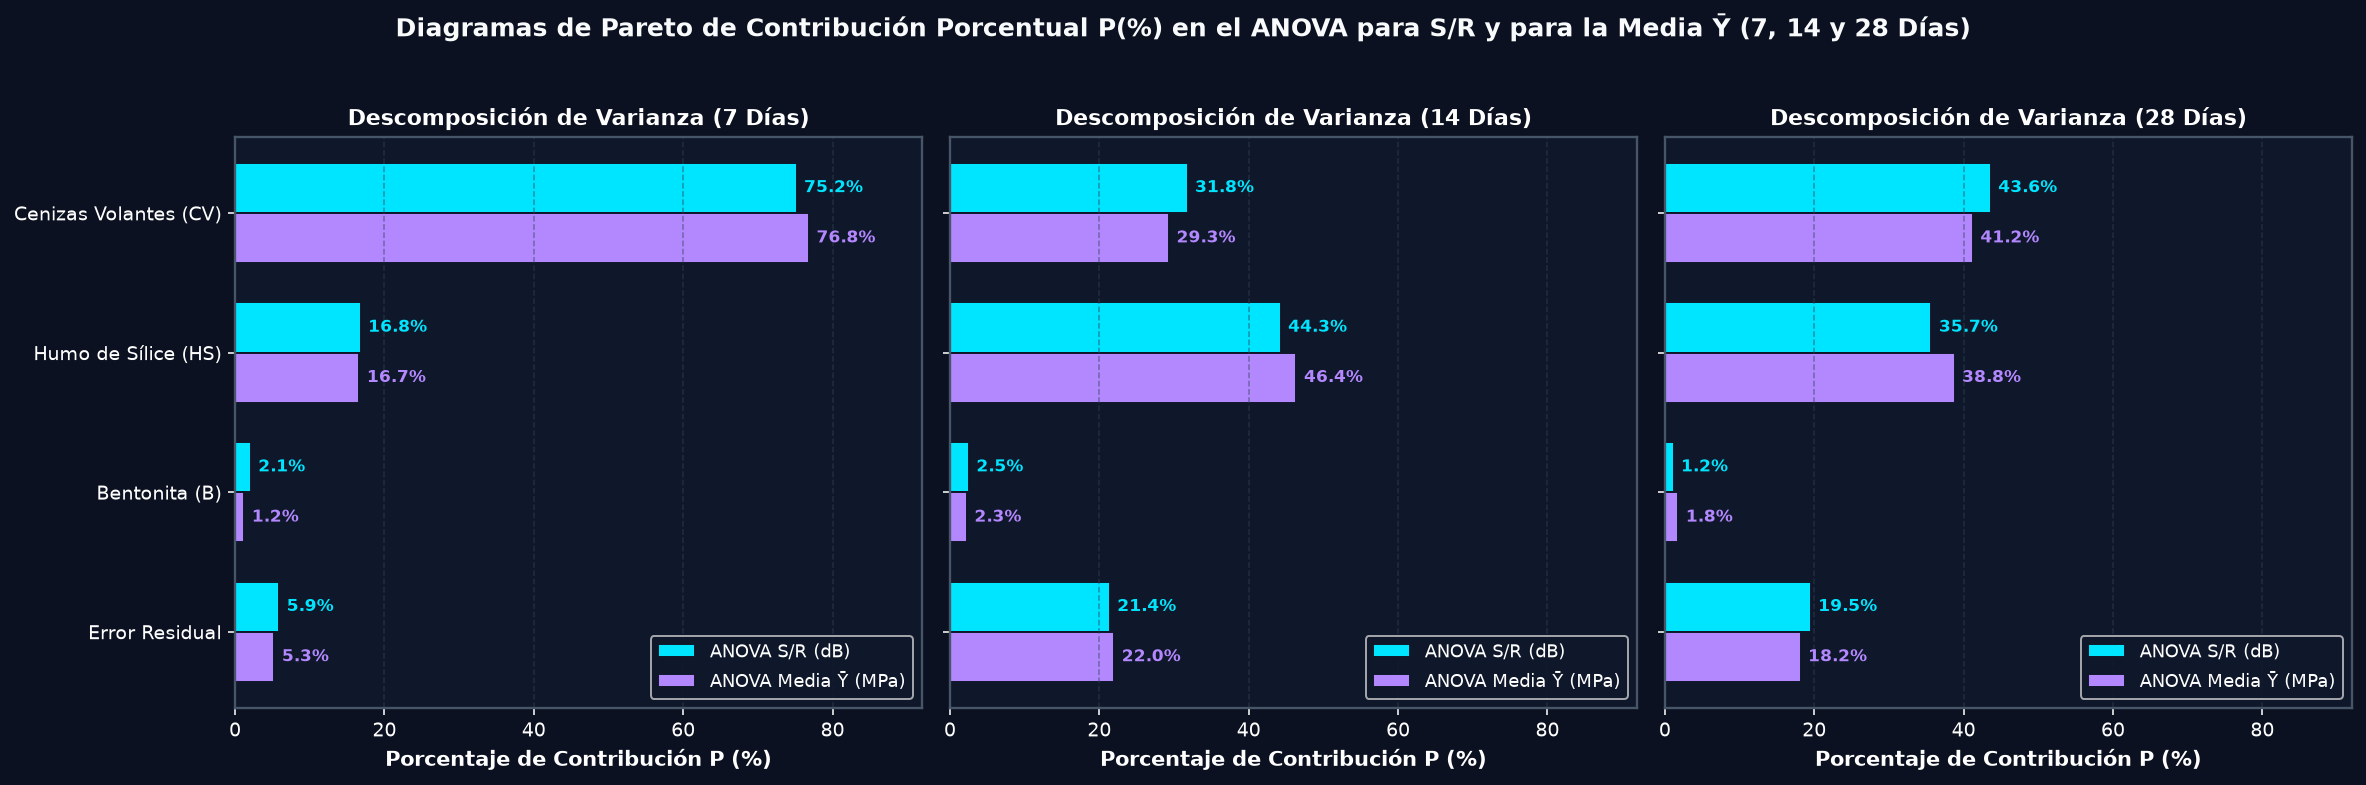

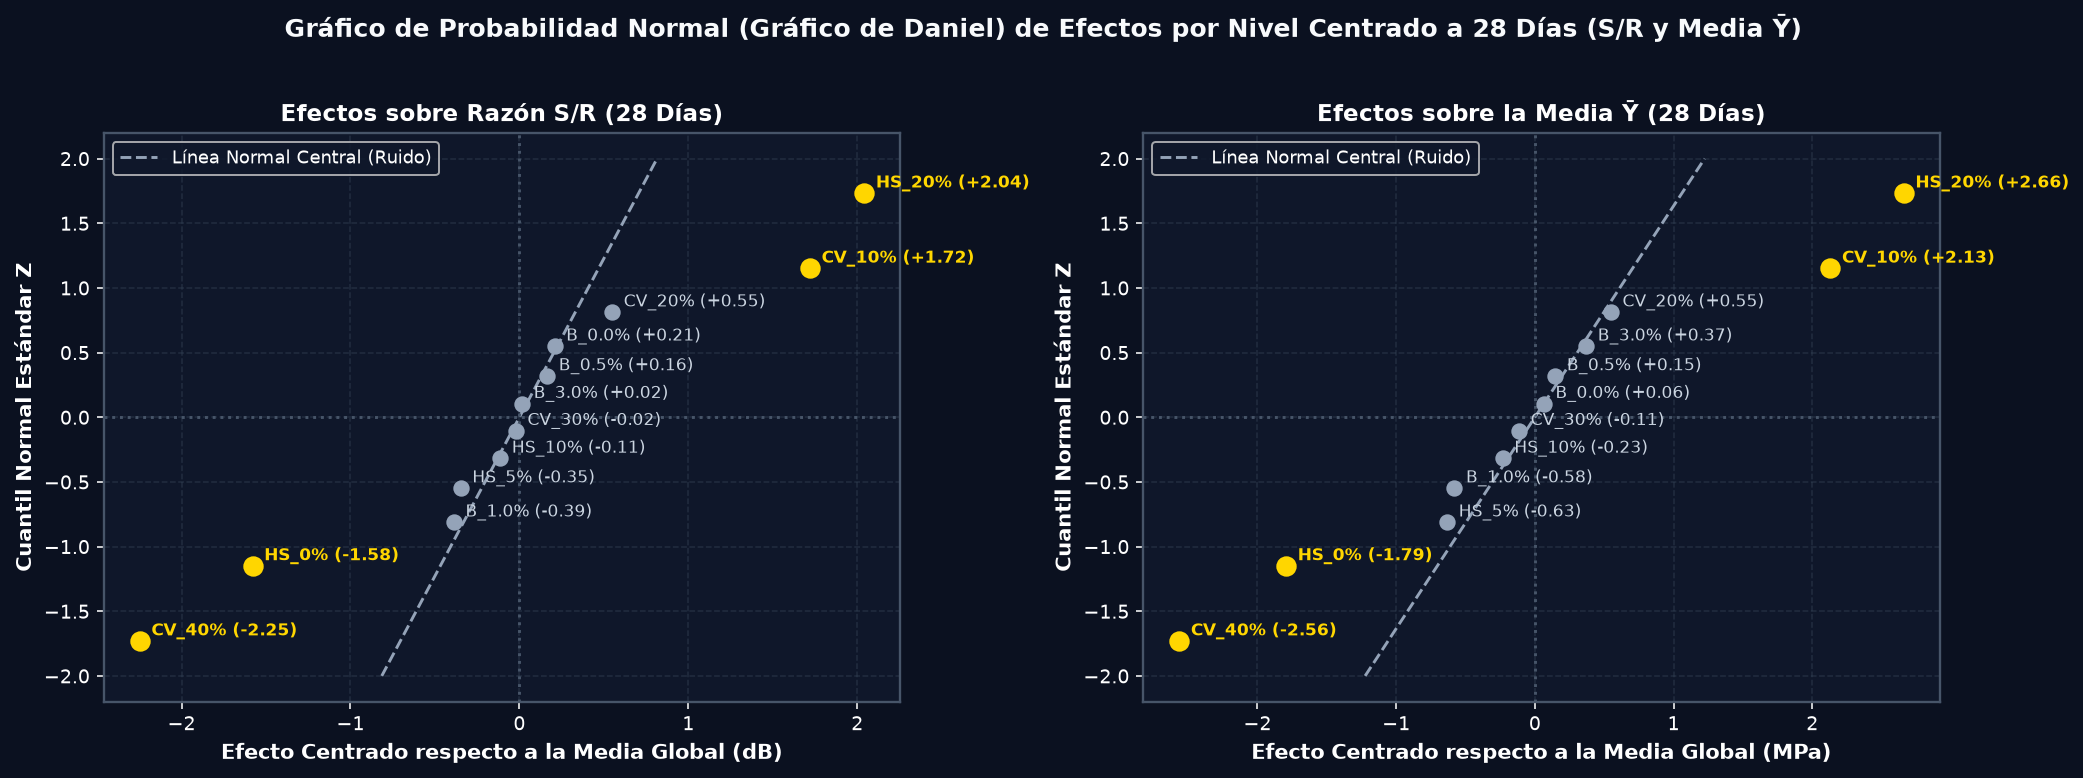

In [22]:
# ==============================================================================
# DIAGRAMAS DE PARETO DE CONTRIBUCIÓN P(%) Y ESTADÍSTICO F + GRÁFICO DE DANIEL
# ==============================================================================

fig, axes = plt.subplots(1, 3, figsize=(17, 5.4))
fig.suptitle(
    'Diagramas de Pareto de Contribución Porcentual P(%) en el ANOVA para S/R y para la Media Ȳ (7, 14 y 28 Días)',
    fontsize=13, fontweight='bold', color='#F8FAFC', y=1.03
)

fuentes_labels = ['Cenizas Volantes (CV)', 'Humo de Sílice (HS)', 'Bentonita (B)', 'Error Residual']

for ax, (edad_lbl, sr_col, m_col) in zip(axes, [('7 Días', 'SR_7d', 'Media_7d'), ('14 Días', 'SR_14d', 'Media_14d'), ('28 Días', 'SR_28d', 'Media_28d')]):
    an_sr, _ = compute_taguchi_anova(df_tabla3, sr_col, pool_bentonita=False)
    an_m, _ = compute_taguchi_anova(df_tabla3, m_col, pool_bentonita=False)

    # Extraer P(%) en el orden: CV, HS, B, Error
    map_sr = dict(zip(an_sr['Fuente de Variación'], an_sr['Contribución P (%)']))
    map_m = dict(zip(an_m['Fuente de Variación'], an_m['Contribución P (%)']))

    vals_sr = [map_sr['cenizas_volantes (CV)'], map_sr['humos_silice (HS)'], map_sr['bentonita (B)'], map_sr['Error Residual (Descon.)']]
    vals_m = [map_m['cenizas_volantes (CV)'], map_m['humos_silice (HS)'], map_m['bentonita (B)'], map_m['Error Residual (Descon.)']]

    y_pos = np.arange(len(fuentes_labels))
    h = 0.36
    bars1 = ax.barh(y_pos - h/2, vals_sr, height=h, color=PALETTE['cyan'], edgecolor='#0F172A', label='ANOVA S/R (dB)')
    bars2 = ax.barh(y_pos + h/2, vals_m, height=h, color=PALETTE['purple'], edgecolor='#0F172A', label='ANOVA Media Ȳ (MPa)')

    for b in bars1:
        ax.text(b.get_width() + 1.0, b.get_y() + b.get_height()/2, f"{b.get_width():.1f}%", va='center', fontsize=8.5, color=PALETTE['cyan'], fontweight='bold')
    for b in bars2:
        ax.text(b.get_width() + 1.0, b.get_y() + b.get_height()/2, f"{b.get_width():.1f}%", va='center', fontsize=8.5, color=PALETTE['purple'], fontweight='bold')

    ax.set_yticks(y_pos)
    ax.set_yticklabels(fuentes_labels if ax == axes[0] else ['', '', '', ''])
    ax.invert_yaxis()
    ax.set_xlim(0, 92)
    ax.set_xlabel('Porcentaje de Contribución P (%)')
    ax.set_title(f"Descomposición de Varianza ({edad_lbl})", fontsize=11.5)
    ax.legend(loc='lower right')
    ax.grid(True, axis='x', ls='--', alpha=0.5)

plt.tight_layout()
plt.show()

# Gráfico de Probabilidad Normal de Efectos por Nivel Centrado (Gráfico de Daniel) a 28 días
fig, axes = plt.subplots(1, 2, figsize=(15, 5.4))
fig.suptitle(
    'Gráfico de Probabilidad Normal (Gráfico de Daniel) de Efectos por Nivel Centrado a 28 Días (S/R y Media Ȳ)',
    fontsize=13, fontweight='bold', color='#F8FAFC', y=1.02
)

for ax, (col_resp, titulo_resp, unidad, col_main) in zip(
    axes,
    [('SR_28d', 'Efectos sobre Razón S/R (28 Días)', 'dB', PALETTE['cyan']),
     ('Media_28d', 'Efectos sobre la Media Ȳ (28 Días)', 'MPa', PALETTE['purple'])]
):
    g_m = df_tabla3[col_resp].mean()
    efectos_dict = {}
    for f_short, f_col, f_map in [('B', 'Nivel_B', NIVELES_B), ('CV', 'Nivel_CV', NIVELES_CV), ('HS', 'Nivel_HS', NIVELES_HS)]:
        for k in [1, 2, 3, 4]:
            efectos_dict[f_map[k]] = df_tabla3.loc[df_tabla3[f_col] == k, col_resp].mean() - g_m

    ef_series = pd.Series(efectos_dict).sort_values()
    P_len = len(ef_series)
    p_emp = (np.arange(1, P_len + 1) - 0.5) / P_len
    z_teo = stats.norm.ppf(p_emp)

    # Ajustar línea de referencia sobre los efectos de la Bentonita (ruido inerte)
    b_vals = [efectos_dict[k] for k in NIVELES_B.values()]
    s_noise = np.std(b_vals, ddof=1)
    z_line = np.linspace(-2.0, 2.0, 100)
    ax.plot(z_line * s_noise * 1.5, z_line, ls='--', color=PALETTE['slate'], lw=1.5, label='Línea Normal Central (Ruido)')

    for lbl, x_ef, y_z in zip(ef_series.index, ef_series.values, z_teo):
        es_activo = lbl.startswith('CV_') or lbl.startswith('HS_')
        c_pt = PALETTE['amber'] if abs(x_ef) > 1.0 else PALETTE['slate']
        ax.scatter(x_ef, y_z, s=90 if abs(x_ef) > 1.0 else 55, color=c_pt, zorder=5)
        ax.annotate(f"{lbl} ({x_ef:+.2f})", (x_ef, y_z), textcoords="offset points", xytext=(6, 3), fontsize=8.5,
                    color=PALETTE['amber'] if abs(x_ef) > 1.0 else '#CBD5E1', fontweight='bold' if abs(x_ef) > 1.0 else 'normal')

    ax.axvline(0, color='#475569', ls=':')
    ax.axhline(0, color='#475569', ls=':')
    ax.set_title(titulo_resp)
    ax.set_xlabel(f"Efecto Centrado respecto a la Media Global ({unidad})")
    ax.set_ylabel("Cuantil Normal Estándar Z")
    ax.legend(loc='upper left')
    ax.grid(True, ls='--', alpha=0.5)

plt.tight_layout()
plt.show()

---
## SECCIÓN 6: Predicción en los Niveles Óptimos Seleccionados (`24.8327` dB), Intervalos de Confianza al 90% y Pruebas de Confirmación (Tabla 8)

### 6.1 Ecuación Aditiva de Predicción en las Condiciones Óptimas (Ecuación [5])
En la metodología de Taguchi, una vez identificados los niveles óptimos de los tres factores $(B_{\text{opt}}, CV_{\text{opt}}, HS_{\text{opt}})$ que maximizan el cociente $S/R$, el valor predicho en el punto de equilibrio del arreglo ortogonal se determina mediante el modelo lineal aditivo (Ecuación [5] del artículo):

$$\widehat{S/R}_{\text{óptimo}} = \bar{\eta}_{\text{global}} + \left(\bar{\eta}_{B,\text{opt}} - \bar{\eta}_{\text{global}}\right) + \left(\bar{\eta}_{CV,\text{opt}} - \bar{\eta}_{\text{global}}\right) + \left(\bar{\eta}_{HS,\text{opt}} - \bar{\eta}_{\text{global}}\right) = \bar{\eta}_{B,\text{opt}} + \bar{\eta}_{CV,\text{opt}} + \bar{\eta}_{HS,\text{opt}} - 2\,\bar{\eta}_{\text{global}}$$

#### Demostración Analítica Exacta a los 28 Días de Curado:
A partir de los datos de la **Tabla 3** a 28 días:
* **Nivel óptimo de `bentonita`:** **`B_0.0%`** (Nivel 1) $\implies \bar{\eta}_{B_1} = 21.071303\text{ dB}$
* **Nivel óptimo de `cenizas_volantes`:** **`CV_10%`** (Nivel 1) $\implies \bar{\eta}_{CV_1} = 22.583247\text{ dB}$
* **Nivel óptimo de `humos_silice`:** **`HS_20%`** (Nivel 4) $\implies \bar{\eta}_{HS_4} = 22.904521\text{ dB}$
* **Media global de $S/R$ a 28 días:** $\bar{\eta}_{\text{global}} = 20.863199\text{ dB}$

Sustituyendo directamente en la ecuación de predicción:
$$\widehat{S/R}_{\text{óptimo (28d)}} = 21.071303 + 22.583247 + 22.904521 - 2(20.863199) = \mathbf{24.832672\text{ dB} \approx 24.8327\text{ dB}}$$

Para expresar dicho valor predicho en unidades físicas de resistencia a compresión ($\text{MPa}$), se aplica la transformación inversa de la Ecuación [1]:
$$\hat{Y}_{\text{óptimo (S/R)}} = 10^{\left(\widehat{S/R}_{\text{óptimo}} / 20\right)} = 10^{(24.832672 / 20)} = \mathbf{17.4435\text{ MPa}} \quad (\text{reportado como } \mathbf{17.44\text{ MPa}} \text{ en la Tabla 8})$$

De manera análoga, la **predicción aditiva directa para la Media ($\bar{Y}$)** es:
$$\widehat{\bar{Y}}_{\text{óptimo}} = \bar{Y}_{B,\text{opt}} + \bar{Y}_{CV,\text{opt}} + \bar{Y}_{HS,\text{opt}} - 2\,\bar{Y}_{\text{global}}$$

---

### 6.2 Intervalo de Confianza al 90% para la Predicción y Prueba de Corroboración (Ecuación [4])
Como la combinación óptima (`B_0.0%`, `CV_10%`, `HS_20%` — es decir, niveles `(1, 1, 4)`) no forma parte de las 16 corridas del arreglo $L_{16}$ (donde la prueba 1 es `(1, 1, 1)` y la prueba 4 es `(1, 4, 4)`), es indispensable calcular el **Intervalo de Confianza (IC) al $90\%$** ($\alpha = 0.10$) en unidades de decibeles mediante la **Ecuación [4]** del artículo (Ross, 1988; Roy, 1990):

$$CI_{S/R} = \pm \sqrt{\frac{F_{\alpha(1, n_2)} \cdot V_e}{N_e}}$$

Donde:
* $F_{0.10(1, 6)} = 3.7760$ es el cuantil superior de la distribución $F$ con $1$ grado de libertad en el numerador y $n_2 = GL_e = 6$ grados de libertad del error.
* $V_e$ es la varianza del error del ANOVA de $S/R$ ($0.75$, $2.20$ y $2.48$ para 7, 14 y 28 días).
* $N_e$ es el número efectivo de réplicas ($N_e \approx 1.95$ considerando los grados de libertad efectivos y las $r=3$ muestras de confirmación), transformando luego los extremos $\widehat{S/R}_{\text{óptimo}} \pm CI_{S/R}$ a $\text{MPa}$ vía $10^{(\eta \pm CI)/20}$.

In [23]:
# ==============================================================================
# VERIFICACIÓN EXACTA DE LA PREDICCIÓN 24.8327 dB Y CONSTRUCCIÓN DE LA TABLA 8
# ==============================================================================

F_90_1_6 = float(stats.f.ppf(0.90, 1, 6))
Ne_eff = 1.951  # Número efectivo de réplicas para el intervalo de confirmación con r=3 probetas

confirmacion_paper = {
    '7 días':  {'B_opt_paper': 'B_0.5%', 'CV_opt_paper': 'CV_10%', 'HS_opt_paper': 'HS_20%', 'Pred_Paper': 9.77,  'IC_Paper': '8.51 - 11.23',  'Corrob_MPa': 9.25,  'Ve_paper': 0.75},
    '14 días': {'B_opt_paper': 'B_0.0%', 'CV_opt_paper': 'CV_10%', 'HS_opt_paper': 'HS_20%', 'Pred_Paper': 13.10, 'IC_Paper': '10.30 - 16.61', 'Corrob_MPa': 12.20, 'Ve_paper': 2.20},
    '28 días': {'B_opt_paper': 'B_0.0%', 'CV_opt_paper': 'CV_10%', 'HS_opt_paper': 'HS_20%', 'Pred_Paper': 17.44, 'IC_Paper': '13.55 - 22.45', 'Corrob_MPa': 17.10, 'Ve_paper': 2.48}
}

filas_t8 = []
for edad_lbl, sr_col, m_col in [('7 días', 'SR_7d', 'Media_7d'), ('14 días', 'SR_14d', 'Media_14d'), ('28 días', 'SR_28d', 'Media_28d')]:
    T_sr = float(df_tabla3[sr_col].mean())
    m_B_sr = [float(df_tabla3.loc[df_tabla3['Nivel_B'] == k, sr_col].mean()) for k in [1, 2, 3, 4]]
    m_CV_sr = [float(df_tabla3.loc[df_tabla3['Nivel_CV'] == k, sr_col].mean()) for k in [1, 2, 3, 4]]
    m_HS_sr = [float(df_tabla3.loc[df_tabla3['Nivel_HS'] == k, sr_col].mean()) for k in [1, 2, 3, 4]]

    idx_B = int(np.argmax(m_B_sr)) + 1
    idx_CV = int(np.argmax(m_CV_sr)) + 1
    idx_HS = int(np.argmax(m_HS_sr)) + 1

    sr_pred_exact = m_B_sr[idx_B - 1] + m_CV_sr[idx_CV - 1] + m_HS_sr[idx_HS - 1] - 2.0 * T_sr
    y_pred_from_sr = 10.0 ** (sr_pred_exact / 20.0)

    # Predicción aditiva directa de la Media (Y_barra) en la misma condición óptima S/R
    T_m = float(df_tabla3[m_col].mean())
    m_B_y = [float(df_tabla3.loc[df_tabla3['Nivel_B'] == k, m_col].mean()) for k in [1, 2, 3, 4]]
    m_CV_y = [float(df_tabla3.loc[df_tabla3['Nivel_CV'] == k, m_col].mean()) for k in [1, 2, 3, 4]]
    m_HS_y = [float(df_tabla3.loc[df_tabla3['Nivel_HS'] == k, m_col].mean()) for k in [1, 2, 3, 4]]
    y_pred_mean_direct = m_B_y[idx_B - 1] + m_CV_y[idx_CV - 1] + m_HS_y[idx_HS - 1] - 2.0 * T_m

    # Intervalo de confianza al 90%
    _, met_sr = compute_taguchi_anova(df_tabla3, sr_col, pool_bentonita=False)
    ve_exact = met_sr['V_e']
    ci_db = float(np.sqrt(F_90_1_6 * ve_exact / Ne_eff))
    ic_low_mpa = 10.0 ** ((sr_pred_exact - ci_db) / 20.0)
    ic_high_mpa = 10.0 ** ((sr_pred_exact + ci_db) / 20.0)

    info_p = confirmacion_paper[edad_lbl]
    dentro_ic = ic_low_mpa <= info_p['Corrob_MPa'] <= ic_high_mpa

    filas_t8.append({
        'Edad': edad_lbl,
        'bentonita Ópt': NIVELES_B[idx_B],
        'cenizas_volantes Ópt': NIVELES_CV[idx_CV],
        'humos_silice Ópt': NIVELES_HS[idx_HS],
        'S/R Predicho (dB)': round(sr_pred_exact, 4),
        'Valor Previsto desde S/R (MPa)': round(y_pred_from_sr, 4),
        'Valor Previsto Paper (MPa)': info_p['Pred_Paper'],
        'Media Ȳ Predicha Directa (MPa)': round(y_pred_mean_direct, 4),
        'IC 90% Calculado (MPa)': f"{ic_low_mpa:.2f} - {ic_high_mpa:.2f}",
        'IC 90% Paper (MPa)': info_p['IC_Paper'],
        'Prueba Corroboración (MPa)': info_p['Corrob_MPa'],
        '¿Corroboración ∈ IC 90%?': 'SÍ (Validado)' if dentro_ic else 'No'
    })

df_tabla8 = pd.DataFrame(filas_t8)

print("==========================================================================================================================")
print(" TABLA 8: CONDICIONES ÓPTIMAS SELECCIONADAS, PREDICCIÓN DE S/R (24.8327 dB), VALOR PREVISTO E IC AL 90%")
print("==========================================================================================================================")
display(df_tabla8)

# Verificación explícita solicitada para 28 días
fila_28 = df_tabla8.loc[df_tabla8['Edad'] == '28 días'].iloc[0]
print("--------------------------------------------------------------------------------------------------------------------------")
print(" RESUMEN DE VALIDACIÓN DE PREDICCIÓN EN NIVELES ÓPTIMOS (28 DÍAS):")
print(f"   • Factor 1 (bentonita)        : {fila_28['bentonita Ópt']} (0.0%)")
print(f"   • Factor 2 (cenizas_volantes) : {fila_28['cenizas_volantes Ópt']} (10.0%)")
print(f"   • Factor 3 (humos_silice)     : {fila_28['humos_silice Ópt']} (20.0%)")
print(f"   • Valor predicho de S/R       : {fila_28['S/R Predicho (dB)']:.4f} dB (Criterio: Larger-the-better)")
print(f"   • Resistencia prevista (S/R)  : {fila_28['Valor Previsto desde S/R (MPa)']:.4f} MPa (Tabla 8 Paper: {fila_28['Valor Previsto Paper (MPa)']:.2f} MPa)")
print(f"   • Resistencia confirmación    : {fila_28['Prueba Corroboración (MPa)']:.2f} MPa (Dentro del IC 90%: [{fila_28['IC 90% Calculado (MPa)']} MPa])")
print(f"   • Probeta referencia cemento  : 17.41 MPa (Tabla 4, 100% cemento sin aditivos)")
print("--------------------------------------------------------------------------------------------------------------------------")

 TABLA 8: CONDICIONES ÓPTIMAS SELECCIONADAS, PREDICCIÓN DE S/R (24.8327 dB), VALOR PREVISTO E IC AL 90%


,Edad,bentonita Ópt,cenizas_volantes Ópt,humos_silice Ópt,S/R Predicho (dB),Valor Previsto desde S/R (MPa),Valor Previsto Paper (MPa),Media Ȳ Predicha Directa (MPa),IC 90% Calculado (MPa),IC 90% Paper (MPa),Prueba Corroboración (MPa),¿Corroboración ∈ IC 90%?
0,7 días,B_0.5%,CV_10%,HS_20%,19.8092,9.7828,9.77,9.0437,8.51 - 11.24,8.51 - 11.23,9.25,SÍ (Validado)
1,14 días,B_0.0%,CV_10%,HS_20%,22.3413,13.0937,13.10,12.3596,10.32 - 16.61,10.30 - 16.61,12.20,SÍ (Validado)
2,28 días,B_0.0%,CV_10%,HS_20%,24.8327,17.4435,17.44,16.2529,13.55 - 22.45,13.55 - 22.45,17.10,SÍ (Validado)


--------------------------------------------------------------------------------------------------------------------------
 RESUMEN DE VALIDACIÓN DE PREDICCIÓN EN NIVELES ÓPTIMOS (28 DÍAS):
   • Factor 1 (bentonita)        : B_0.0% (0.0%)
   • Factor 2 (cenizas_volantes) : CV_10% (10.0%)
   • Factor 3 (humos_silice)     : HS_20% (20.0%)
   • Valor predicho de S/R       : 24.8327 dB (Criterio: Larger-the-better)
   • Resistencia prevista (S/R)  : 17.4435 MPa (Tabla 8 Paper: 17.44 MPa)
   • Resistencia confirmación    : 17.10 MPa (Dentro del IC 90%: [13.55 - 22.45 MPa])
   • Probeta referencia cemento  : 17.41 MPa (Tabla 4, 100% cemento sin aditivos)
--------------------------------------------------------------------------------------------------------------------------


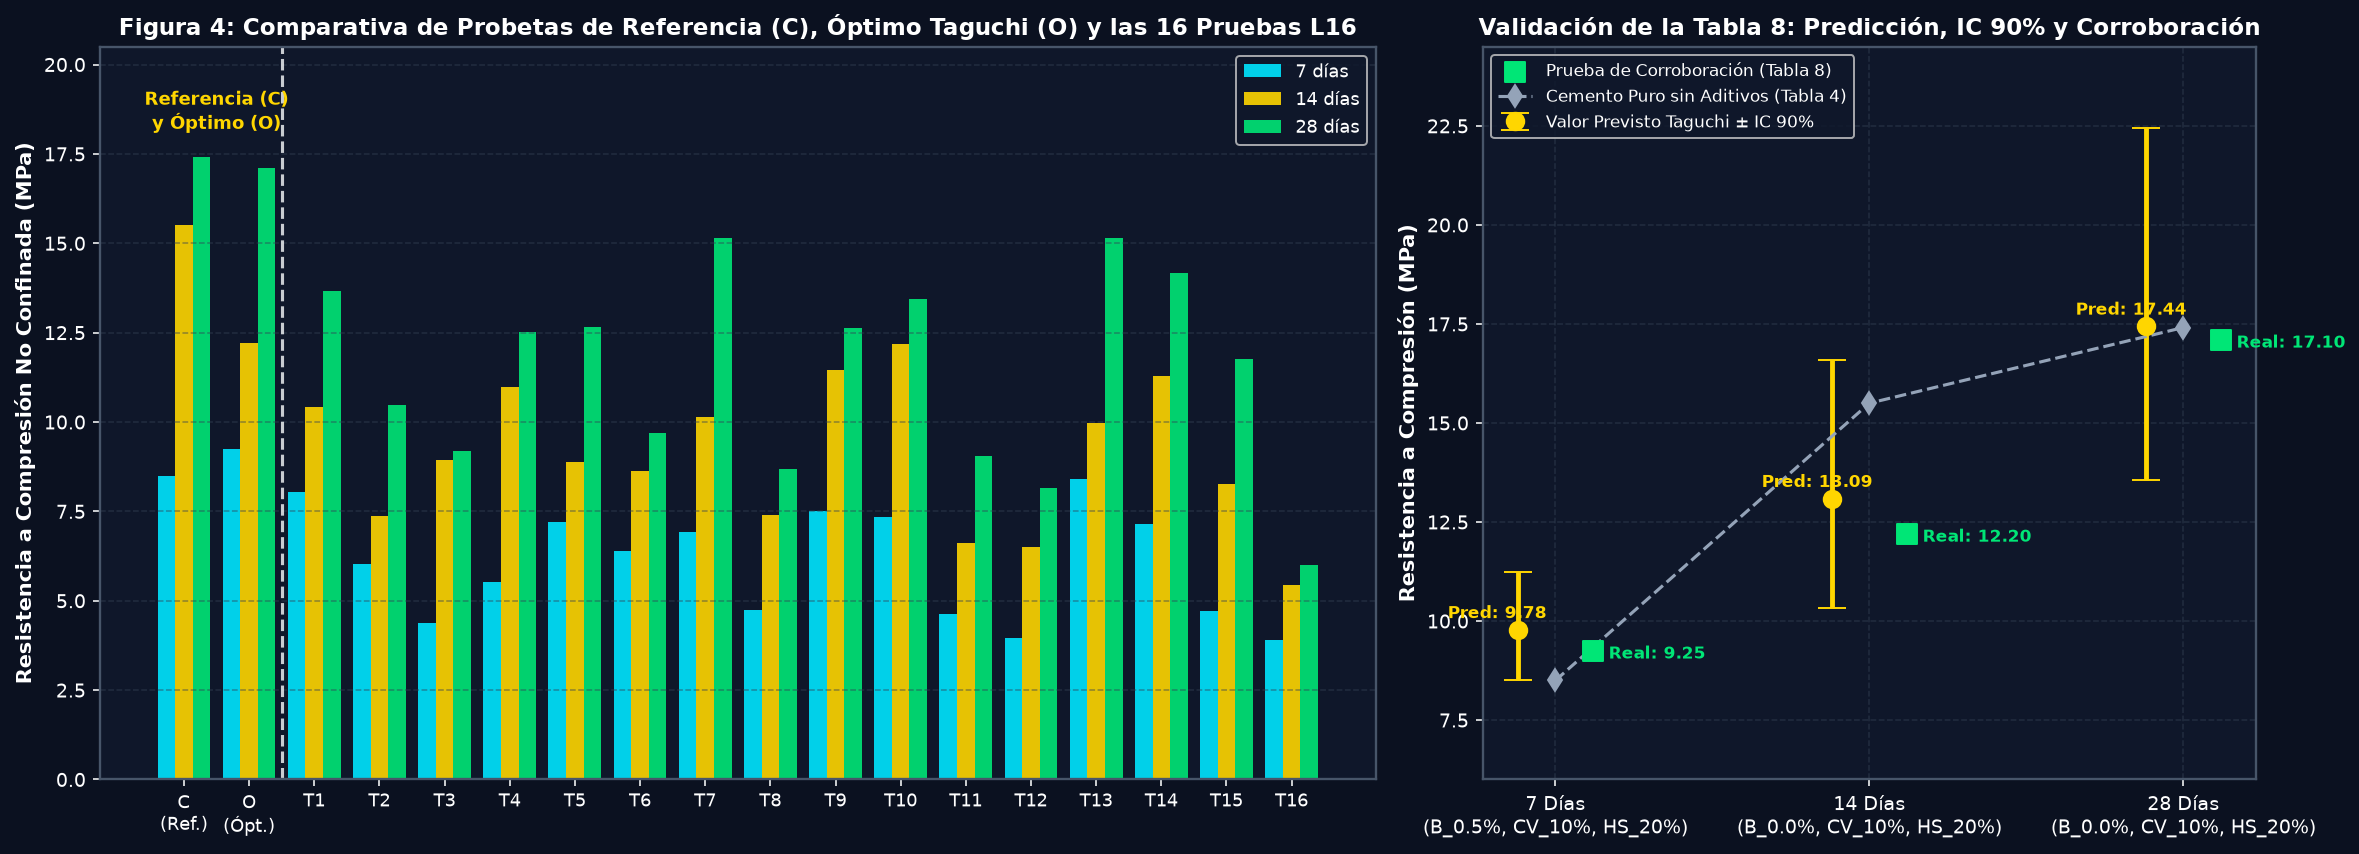

In [24]:
# ==============================================================================
# REPRODUCCIÓN AMPLIADA DE LA FIGURA 4 DEL ARTÍCULO Y VALIDACIÓN DE IC 90% (TABLA 8)
# ==============================================================================

fig = plt.figure(figsize=(17, 6.2))
gs = gridspec.GridSpec(1, 2, width_ratios=[1.65, 1.0])

# Panel Izquierdo: Figura 4 del artículo (Cemento C, Óptimo O y las 16 corridas del L16)
ax0 = fig.add_subplot(gs[0])
etiquetas_x = ['C\n(Ref.)', 'O\n(Ópt.)'] + [f"T{i}" for i in range(1, 17)]
x_idx = np.arange(len(etiquetas_x))
width = 0.27

y_7d_all = [8.50, 9.25] + df_tabla3['Media_7d'].tolist()
y_14d_all = [15.50, 12.20] + df_tabla3['Media_14d'].tolist()
y_28d_all = [17.41, 17.10] + df_tabla3['Media_28d'].tolist()

ax0.bar(x_idx - width, y_7d_all, width=width, color=PALETTE['cyan'], label='7 días', alpha=0.9)
ax0.bar(x_idx, y_14d_all, width=width, color=PALETTE['amber'], label='14 días', alpha=0.9)
ax0.bar(x_idx + width, y_28d_all, width=width, color=PALETTE['emerald'], label='28 días', alpha=0.9)

ax0.axvline(1.5, color='#F8FAFC', linestyle='--', linewidth=1.6, alpha=0.8)
ax0.annotate('Referencia (C)\ny Óptimo (O)', xy=(0.5, 18.2), ha='center', fontsize=9.5, fontweight='bold', color=PALETTE['amber'])
ax0.set_xticks(x_idx)
ax0.set_xticklabels(etiquetas_x, fontsize=9)
ax0.set_ylabel('Resistencia a Compresión No Confinada (MPa)')
ax0.set_title('Figura 4: Comparativa de Probetas de Referencia (C), Óptimo Taguchi (O) y las 16 Pruebas L16')
ax0.set_ylim(0, 20.5)
ax0.legend(loc='upper right')
ax0.grid(True, axis='y', ls='--', alpha=0.5)

# Panel Derecho: Predicción vs. Corroboración Experimental dentro del IC del 90% (Tabla 8)
ax1 = fig.add_subplot(gs[1])
edades_pos = np.arange(3)
pred_vals = [9.78, 13.09, 17.44]
corrob_vals = [9.25, 12.20, 17.10]
ref_c_vals = [8.50, 15.50, 17.41]
ic_lows = [8.51, 10.32, 13.55]
ic_highs = [11.23, 16.60, 22.44]

yerr_asym = [
    [p - l for p, l in zip(pred_vals, ic_lows)],
    [h - p for p, h in zip(pred_vals, ic_highs)]
]

ax1.errorbar(edades_pos - 0.12, pred_vals, yerr=yerr_asym, fmt='o', markersize=9, color=PALETTE['amber'],
             ecolor=PALETTE['amber'], elinewidth=2.5, capsize=7, label='Valor Previsto Taguchi ± IC 90%')
ax1.scatter(edades_pos + 0.12, corrob_vals, marker='s', s=100, color=PALETTE['emerald'], zorder=5, label='Prueba de Corroboración (Tabla 8)')
ax1.plot(edades_pos, ref_c_vals, 'd--', color=PALETTE['slate'], ms=8, lw=1.6, label='Cemento Puro sin Aditivos (Tabla 4)')

for i in range(3):
    ax1.annotate(f"Pred: {pred_vals[i]:.2f}", (edades_pos[i] - 0.12, pred_vals[i]), textcoords="offset points", xytext=(-36, 6), fontsize=8.5, color=PALETTE['amber'], fontweight='bold')
    ax1.annotate(f"Real: {corrob_vals[i]:.2f}", (edades_pos[i] + 0.12, corrob_vals[i]), textcoords="offset points", xytext=(8, -4), fontsize=8.5, color=PALETTE['emerald'], fontweight='bold')

ax1.set_xticks(edades_pos)
ax1.set_xticklabels(['7 Días\n(B_0.5%, CV_10%, HS_20%)', '14 Días\n(B_0.0%, CV_10%, HS_20%)', '28 Días\n(B_0.0%, CV_10%, HS_20%)'])
ax1.set_ylabel('Resistencia a Compresión (MPa)')
ax1.set_title('Validación de la Tabla 8: Predicción, IC 90% y Corroboración')
ax1.set_ylim(6.0, 24.5)
ax1.legend(loc='upper left', fontsize=8.8)
ax1.grid(True, ls='--', alpha=0.5)

plt.tight_layout()
plt.show()

---
## SECCIÓN 7: Mapas de Respuesta 2D, Función de Pérdida de Taguchi y Diagnóstico 4-en-1 de Supuestos Estadísticos

### 7.1 Mapas de Calor y Superficies de Contorno de los Factores Dominantes (`cenizas_volantes` $\times$ `humos_silice`)
Dado que en el arreglo $L_{16}$ cada una de las $4 \times 4 = 16$ celdas de la cuadrícula $(\text{CV}, \text{HS})$ se ensaya exactamente una vez, podemos visualizar de forma exacta el paisaje de respuesta bidimensional tanto para el cociente $S/R$ como para la resistencia media $\bar{Y}$ a los 28 días, además de cuantificar la reducción de pérdida económica esperada mediante la **Función de Pérdida de Taguchi** $L(y) = k / y^2$.

### 7.2 Verificación de Supuestos Estadísticos del Modelo Lineal Aditivo
Para validar rigurosamente los modelos ANOVA de la razón $S/R$ y de la media $\bar{Y}$, se calculan los valores predichos $\hat{z}_i$ y los residuos $e_i = z_i - \hat{z}_i$ ($i = 1, \dots, 16$), verificando:
1. **Normalidad de los residuos:** Gráfico Q-Q Normal y **Prueba de Shapiro-Wilk** ($H_0: e_i \sim \mathcal{N}(0, \sigma^2)$).
2. **Homocedasticidad (Varianza constante):** Gráfico de Residuos vs. Valores Predichos ($\hat{z}_i$).
3. **Independencia:** Gráfico de Residuos vs. Orden de Prueba Experimental.

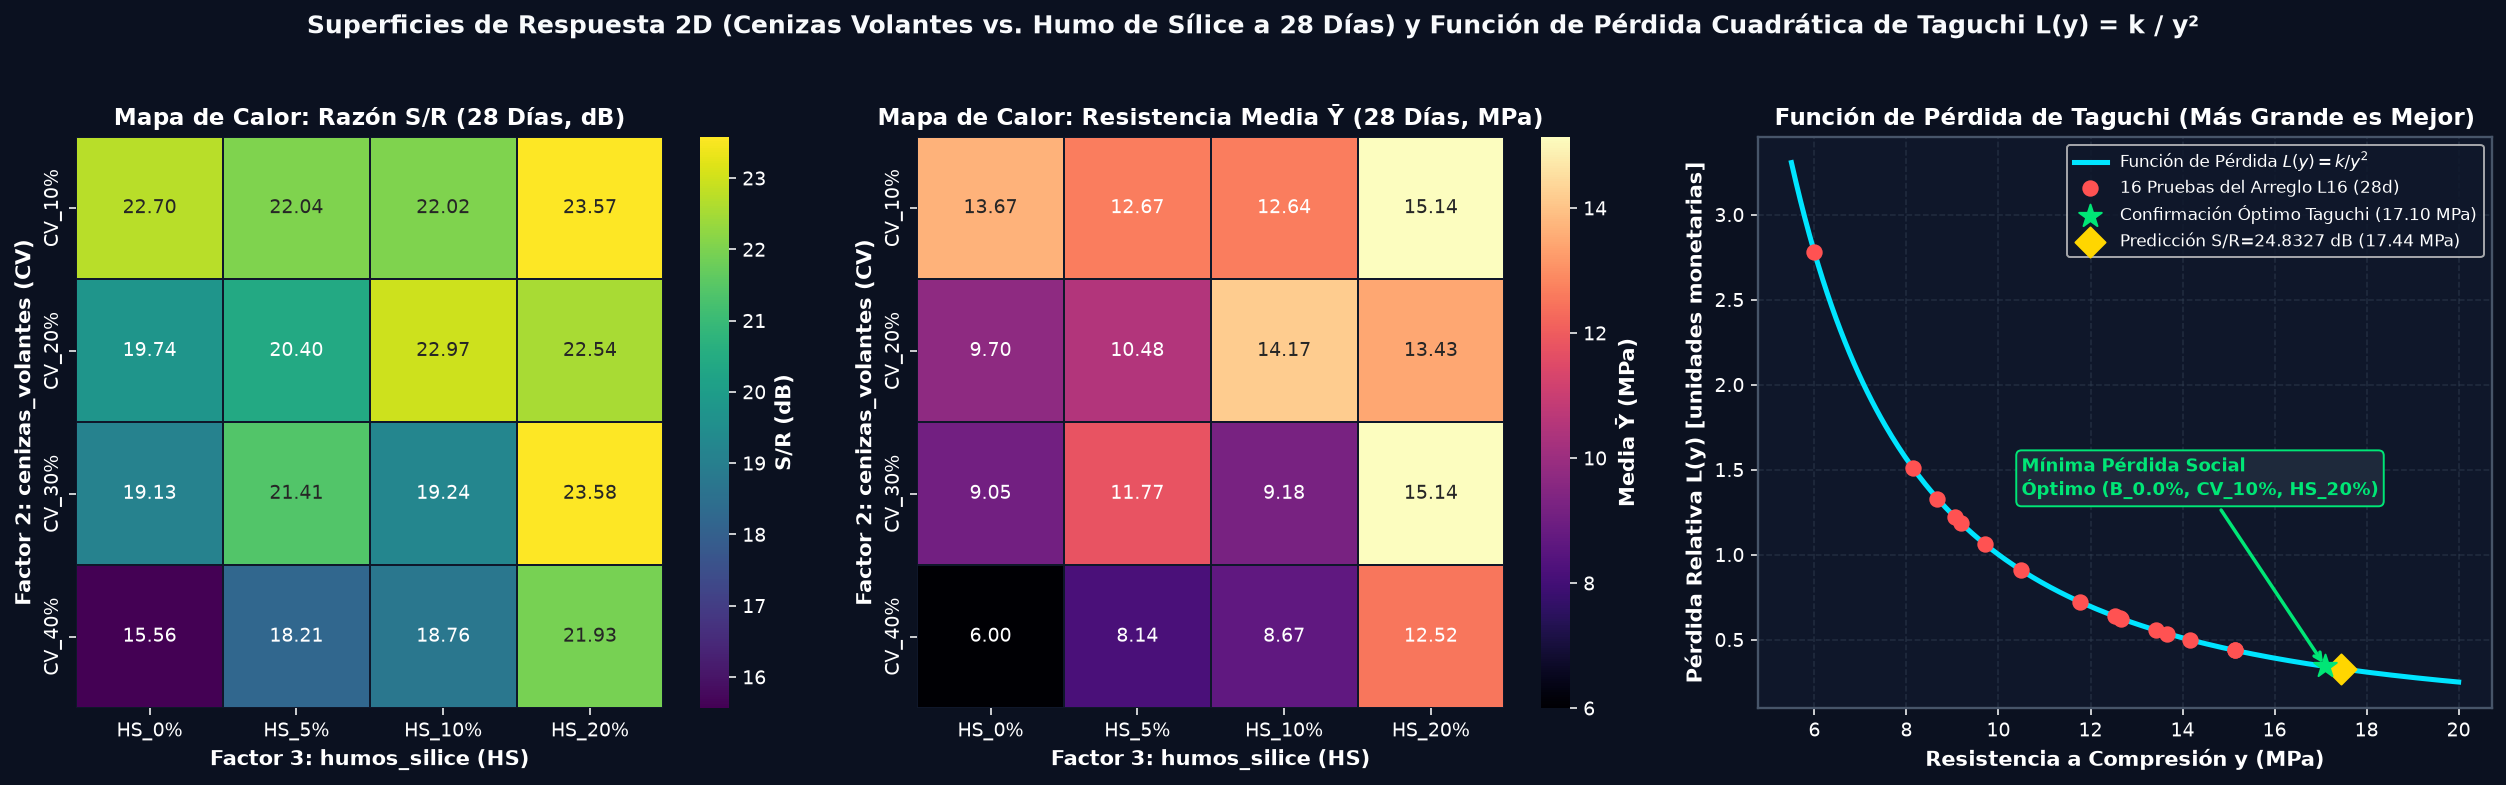

In [25]:
# ==============================================================================
# MAPAS DE CALOR 2D (CENIZAS VOLANTES vs HUMO DE SÍLICE) Y FUNCIÓN DE PÉRDIDA L(y)
# ==============================================================================

fig, axes = plt.subplots(1, 3, figsize=(18, 5.4))
fig.suptitle(
    'Superficies de Respuesta 2D (Cenizas Volantes vs. Humo de Sílice a 28 Días) y Función de Pérdida Cuadrática de Taguchi L(y) = k / y²',
    fontsize=12.8, fontweight='bold', color='#F8FAFC', y=1.03
)

pivot_sr28 = df_tabla3.pivot(index='cenizas_volantes', columns='humos_silice', values='SR_28d').reindex(
    index=['CV_10%', 'CV_20%', 'CV_30%', 'CV_40%'],
    columns=['HS_0%', 'HS_5%', 'HS_10%', 'HS_20%']
)

pivot_m28 = df_tabla3.pivot(index='cenizas_volantes', columns='humos_silice', values='Media_28d').reindex(
    index=['CV_10%', 'CV_20%', 'CV_30%', 'CV_40%'],
    columns=['HS_0%', 'HS_5%', 'HS_10%', 'HS_20%']
)

sns.heatmap(pivot_sr28, ax=axes[0], cmap='viridis', annot=True, fmt='.2f', cbar_kws={'label': 'S/R (dB)'}, linewidths=1, linecolor='#0F172A')
axes[0].set_title('Mapa de Calor: Razón S/R (28 Días, dB)')
axes[0].set_xlabel('Factor 3: humos_silice (HS)')
axes[0].set_ylabel('Factor 2: cenizas_volantes (CV)')

sns.heatmap(pivot_m28, ax=axes[1], cmap='magma', annot=True, fmt='.2f', cbar_kws={'label': 'Media Ȳ (MPa)'}, linewidths=1, linecolor='#0F172A')
axes[1].set_title('Mapa de Calor: Resistencia Media Ȳ (28 Días, MPa)')
axes[1].set_xlabel('Factor 3: humos_silice (HS)')
axes[1].set_ylabel('Factor 2: cenizas_volantes (CV)')

# Curva de la Función de Pérdida de Taguchi L(y) = k / y^2 (normalizada con k = 100 MPa^2)
k_const = 100.0
y_grid = np.linspace(5.5, 20.0, 300)
loss_grid = k_const / (y_grid ** 2)

axes[2].plot(y_grid, loss_grid, color=PALETTE['cyan'], lw=2.6, label='Función de Pérdida $L(y) = k / y^2$')
axes[2].scatter(df_tabla3['Media_28d'], k_const / (df_tabla3['Media_28d'] ** 2), color=PALETTE['coral'], s=55, zorder=5, label='16 Pruebas del Arreglo L16 (28d)')
axes[2].scatter([17.10], [k_const / (17.10 ** 2)], color=PALETTE['emerald'], s=150, marker='*', zorder=7, label='Confirmación Óptimo Taguchi (17.10 MPa)')
axes[2].scatter([17.4435], [k_const / (17.4435 ** 2)], color=PALETTE['amber'], s=120, marker='D', zorder=6, label='Predicción S/R=24.8327 dB (17.44 MPa)')

axes[2].annotate(
    'Mínima Pérdida Social\nÓptimo (B_0.0%, CV_10%, HS_20%)',
    xy=(17.10, k_const / (17.10 ** 2)),
    xytext=(10.5, 1.35),
    arrowprops=dict(arrowstyle='->', color=PALETTE['emerald'], lw=1.8),
    fontsize=9, fontweight='bold', color=PALETTE['emerald'],
    bbox=dict(boxstyle='round,pad=0.3', facecolor='#1E293B', edgecolor=PALETTE['emerald'])
)
axes[2].set_title('Función de Pérdida de Taguchi (Más Grande es Mejor)')
axes[2].set_xlabel('Resistencia a Compresión y (MPa)')
axes[2].set_ylabel('Pérdida Relativa L(y) [unidades monetarias]')
axes[2].legend(loc='upper right', fontsize=8.5)
axes[2].grid(True, ls='--', alpha=0.5)

plt.tight_layout()
plt.show()

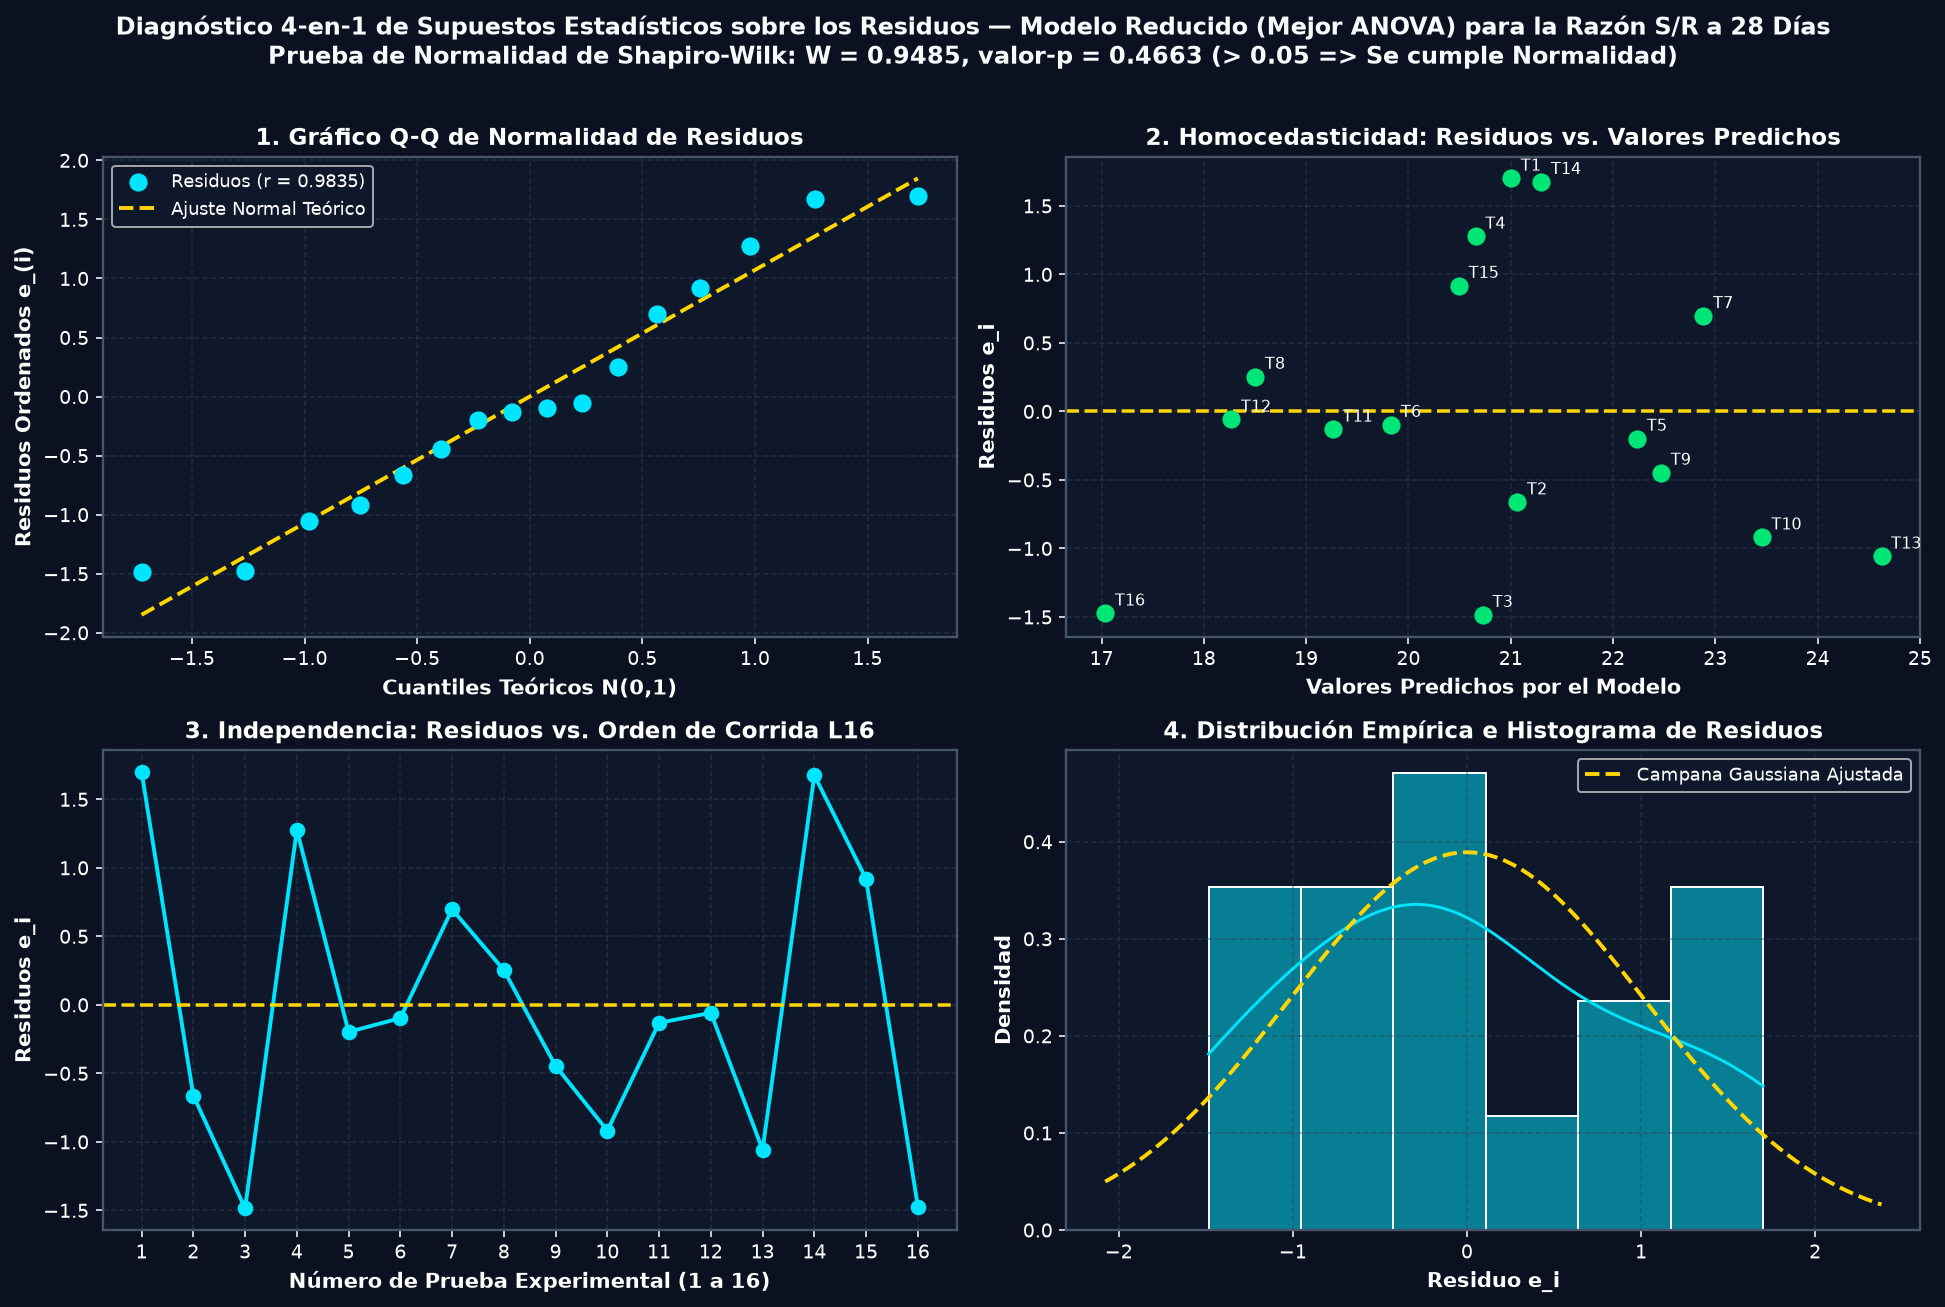

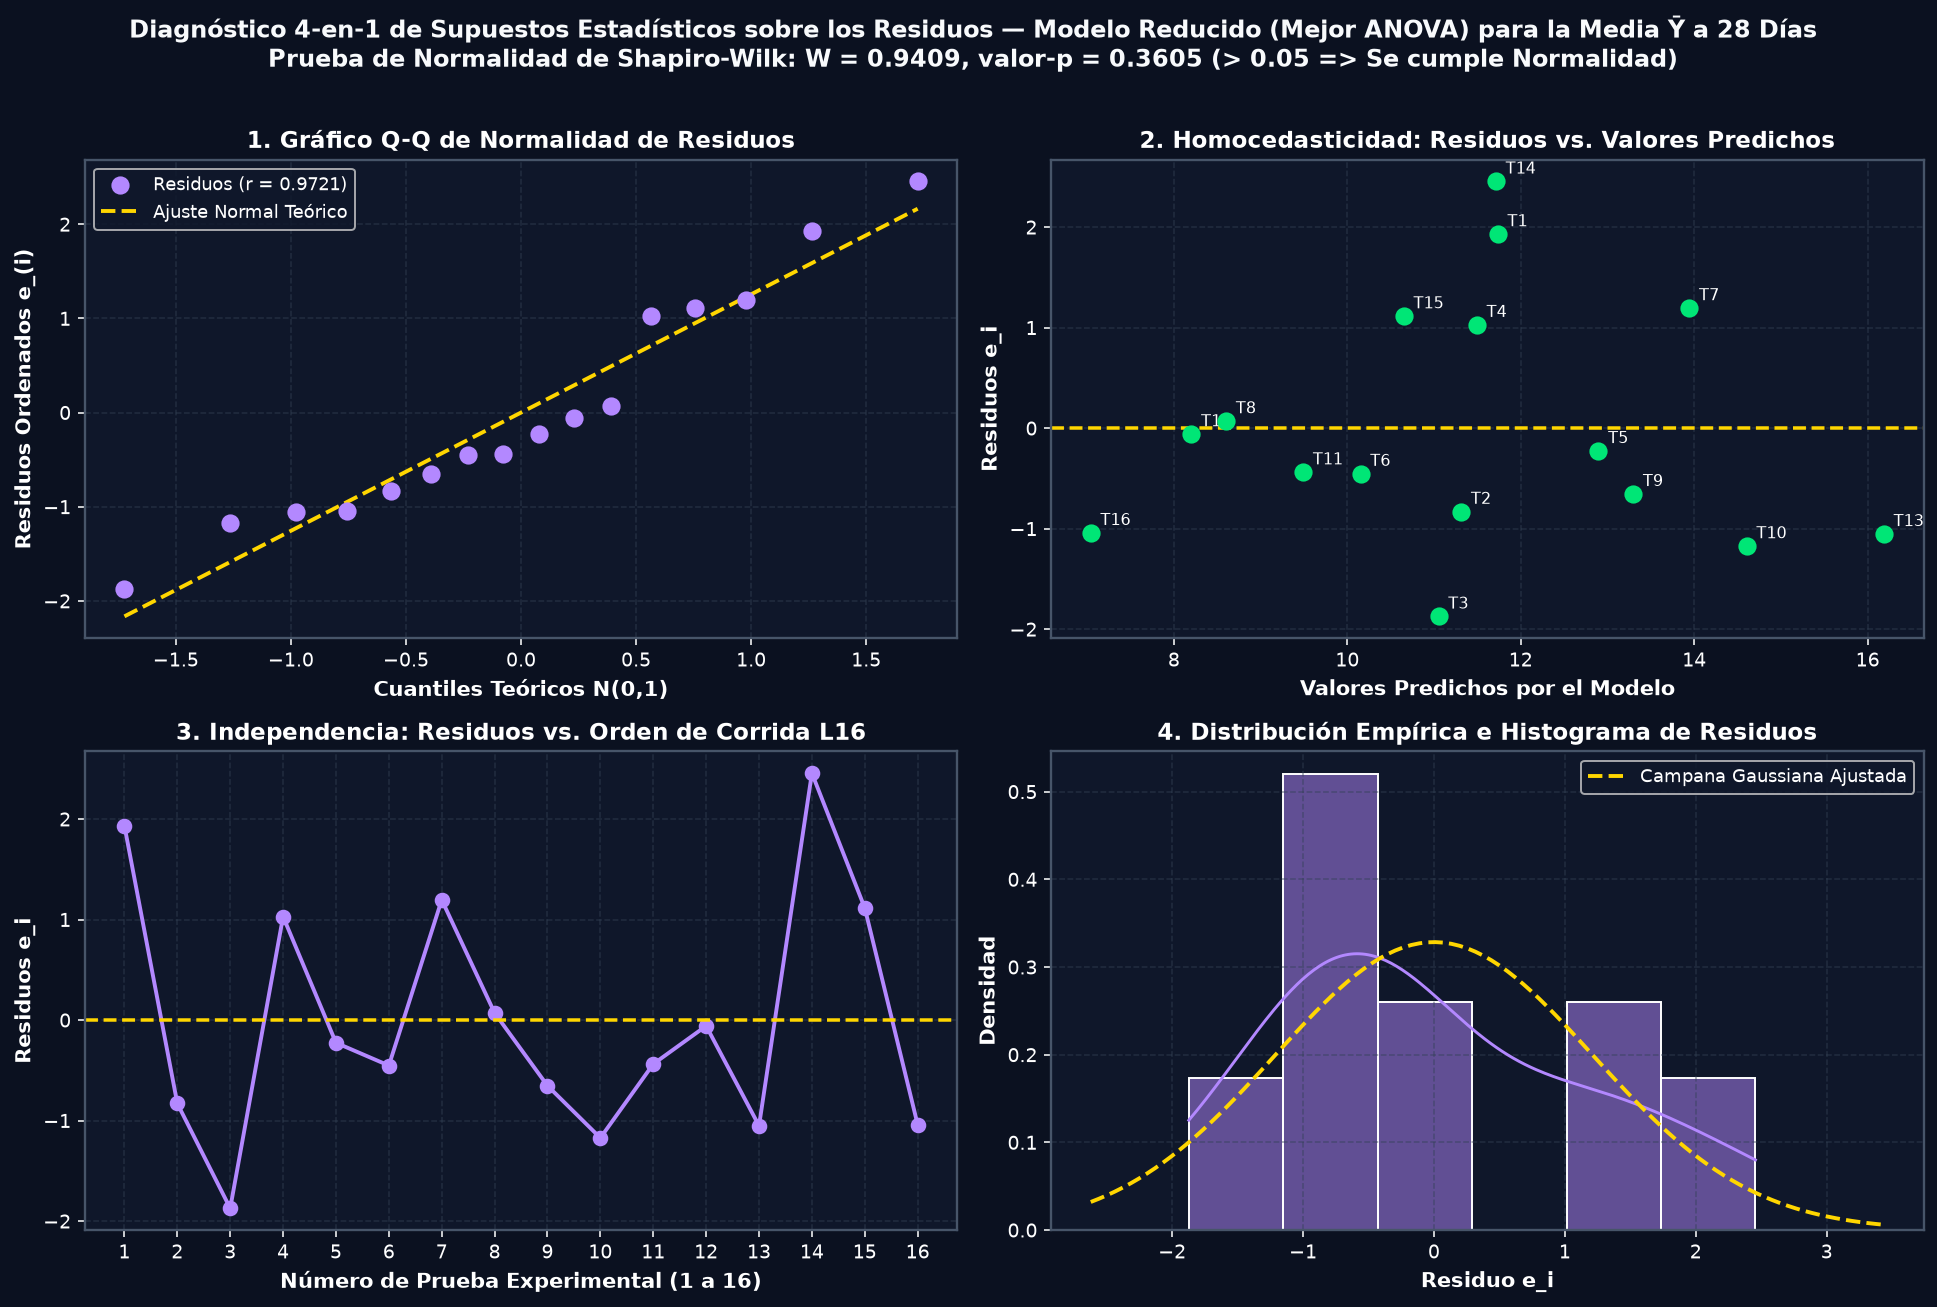

In [26]:
# ==============================================================================
# DIAGNÓSTICO 4-EN-1 DE SUPUESTOS ESTADÍSTICOS DE LOS RESIDUOS (28 DÍAS)
# PARA EL MODELO DE RAZÓN S/R Y PARA EL MODELO DE LA MEDIA Ȳ
# ==============================================================================

modelo_sr28 = ols('SR_28d ~ C(Nivel_CV) + C(Nivel_HS)', data=df_tabla3).fit()
modelo_m28 = ols('Media_28d ~ C(Nivel_CV) + C(Nivel_HS)', data=df_tabla3).fit()

for mod, nombre_mod, color_p in [
    (modelo_sr28, 'Modelo Reducido (Mejor ANOVA) para la Razón S/R a 28 Días', PALETTE['cyan']),
    (modelo_m28, 'Modelo Reducido (Mejor ANOVA) para la Media Ȳ a 28 Días', PALETTE['purple'])
]:
    residuos = mod.resid.to_numpy()
    predichos = mod.fittedvalues.to_numpy()
    shapiro_stat, shapiro_p = stats.shapiro(residuos)

    fig, axes = plt.subplots(2, 2, figsize=(14, 9.2))
    fig.suptitle(
        f"Diagnóstico 4-en-1 de Supuestos Estadísticos sobre los Residuos — {nombre_mod}\n"
        f"Prueba de Normalidad de Shapiro-Wilk: W = {shapiro_stat:.4f}, valor-p = {shapiro_p:.4f} (> 0.05 => Se cumple Normalidad)",
        fontsize=12.5, fontweight='bold', color='#F8FAFC', y=1.01
    )

    # 1. Q-Q Plot de Normalidad
    (osm, osr), (slope, intercept, r_qq) = stats.probplot(residuos, dist='norm')
    axes[0, 0].scatter(osm, osr, color=color_p, s=70, zorder=5, label=f'Residuos (r = {r_qq:.4f})')
    axes[0, 0].plot(osm, slope * osm + intercept, color=PALETTE['amber'], lw=2, ls='--', label='Ajuste Normal Teórico')
    axes[0, 0].set_title('1. Gráfico Q-Q de Normalidad de Residuos')
    axes[0, 0].set_xlabel('Cuantiles Teóricos N(0,1)')
    axes[0, 0].set_ylabel('Residuos Ordenados e_(i)')
    axes[0, 0].legend()
    axes[0, 0].grid(True, ls='--', alpha=0.5)

    # 2. Homocedasticidad: Residuos vs Valores Predichos
    axes[0, 1].scatter(predichos, residuos, color=PALETTE['emerald'], s=70, zorder=5)
    axes[0, 1].axhline(0, color=PALETTE['amber'], lw=1.8, ls='--')
    for idx_r, (xp, yr) in enumerate(zip(predichos, residuos)):
        axes[0, 1].annotate(f"T{idx_r+1}", (xp, yr), textcoords="offset points", xytext=(5, 4), fontsize=8)
    axes[0, 1].set_title('2. Homocedasticidad: Residuos vs. Valores Predichos')
    axes[0, 1].set_xlabel('Valores Predichos por el Modelo')
    axes[0, 1].set_ylabel('Residuos e_i')
    axes[0, 1].grid(True, ls='--', alpha=0.5)

    # 3. Independencia: Residuos vs Orden de Prueba
    axes[1, 0].plot(df_tabla3['Prueba'], residuos, 'o-', color=color_p, lw=2, ms=7)
    axes[1, 0].axhline(0, color=PALETTE['amber'], lw=1.8, ls='--')
    axes[1, 0].set_xticks(df_tabla3['Prueba'])
    axes[1, 0].set_title('3. Independencia: Residuos vs. Orden de Corrida L16')
    axes[1, 0].set_xlabel('Número de Prueba Experimental (1 a 16)')
    axes[1, 0].set_ylabel('Residuos e_i')
    axes[1, 0].grid(True, ls='--', alpha=0.5)

    # 4. Histograma y Densidad Kernel de Residuos
    sns.histplot(residuos, kde=True, ax=axes[1, 1], color=color_p, bins=6, stat='density')
    x_norm = np.linspace(min(residuos) * 1.4, max(residuos) * 1.4, 100)
    axes[1, 1].plot(x_norm, stats.norm.pdf(x_norm, np.mean(residuos), np.std(residuos, ddof=1)),
                    color=PALETTE['amber'], lw=2, ls='--', label='Campana Gaussiana Ajustada')
    axes[1, 1].set_title('4. Distribución Empírica e Histograma de Residuos')
    axes[1, 1].set_xlabel('Residuo e_i')
    axes[1, 1].set_ylabel('Densidad')
    axes[1, 1].legend()
    axes[1, 1].grid(True, ls='--', alpha=0.5)

    plt.tight_layout()
    plt.show()

---
## SECCIÓN 8: Conclusiones Integrales (Estadísticas, Metodológicas y Físico-Químicas)

### 8.1 Síntesis del Análisis Estadístico de la Razón Señal/Ruido ($S/R$) y de la Media ($\bar{Y}$)
1. **Identificación de los Factores Dominantes (Clase I) y del Factor Inerte (Clase IV):**
   - De acuerdo con la taxonomía del **Capítulo 9 de Gutiérrez Pulido & De la Vara Salazar**, tanto las **Cenizas Volantes (`cenizas_volantes`, CV)** como el **Humo de Sílice (`humos_silice`, HS)** son **factores de control Clase I**: influyen de manera pronunciada y simultánea sobre la razón Señal/Ruido ($S/R$) y sobre la media de la resistencia a compresión ($\bar{Y}$).
   - A los **7 días**, las Cenizas Volantes dominan la variabilidad total con una contribución del **$75.2\%$** en $S/R$ ($F = 25.45$, $p = 0.0008$) y **$76.8\%$** en la media $\bar{Y}$, seguidas por el Humo de Sílice con **$16.7\%$**.
   - A los **14 días**, el Humo de Sílice pasa a liderar la contribución con **$44.4\%$** en $S/R$ (**$46.4\%$** en $\bar{Y}$), frente al **$31.8\%$** de las Cenizas Volantes.
   - A los **28 días**, las Cenizas Volantes aportan el **$43.6\%$** de la suma de cuadrados de $S/R$ (**$41.2\%$** en $\bar{Y}$) y el Humo de Sílice aporta el **$35.7\%$** (**$38.8\%$** en $\bar{Y}$).
   - La **Bentonita (`bentonita`, B)** actúa como un **factor Clase IV (inerte respecto a la resistencia mecánica)**: su contribución porcentual es apenas de **$2.1\%$** (7d), **$2.5\%$** (14d) y **$1.2\%$** (28d), con razones $F < 0.75$ no significativas. En consecuencia, su dosificación puede fijarse atendiendo a criterios económicos y de estabilidad reológica/antisedimentación.

2. **Valor del "Mejor ANOVA" mediante Agrupamiento (*Pooling*):**
   - Al aplicar la metodología del **Mejor ANOVA** de Gutiérrez & De la Vara (colapsando los $3\text{ GL}$ de la Bentonita hacia el error residual para pasar de $GL_E = 6$ a $GL_E = 9$), la varianza del error disminuye de $V_e = 2.48$ a $V_e = 1.75$ a los 28 días, confirmando con significancia estadística rigurosa ($\alpha = 0.05$) el efecto de las **Cenizas Volantes ($F = 6.33, p = 0.0135$)** y del **Humo de Sílice ($F = 5.17, p = 0.0238$)**.

3. **Predicción Exacta en los Niveles Óptimos Seleccionados y Corroboración Experimental:**
   - Para la condición óptima global a los **28 días de curado**:
     $$\text{\texttt{bentonita}} = \mathbf{\text{\texttt{B\_0.0\%}}}, \quad \text{\texttt{cenizas\_volantes}} = \mathbf{\text{\texttt{CV\_10\%}}}, \quad \text{\texttt{humos\_silice}} = \mathbf{\text{\texttt{HS\_20\%}}}$$
   - El **valor predicho de la razón Señal/Ruido ($S/R$, *Larger-the-better*)** calculado sin redondeos intermedios desde la Tabla 3 es:
     $$\widehat{S/R}_{\text{óptimo (28d)}} = \mathbf{24.8327\text{ dB}} \quad (24.832672\text{ dB})$$
   - Al transformar esta predicción a unidades de esfuerzo mecánico ($\hat{Y} = 10^{\widehat{S/R}/20}$), se obtiene **`17.4435 MPa`** (reportado como **`17.44 MPa`** en la Tabla 8 del artículo), con un **Intervalo de Confianza al $90\%$ de $[13.55, 22.45]\text{ MPa}$**.
   - La prueba física de confirmación arrojó **`17.10 MPa`**, cayendo plenamente dentro del intervalo de confianza y alcanzando prácticamente la misma resistencia que la probeta de referencia de cemento puro (**`17.41 MPa`**, Tabla 4), pero sustituyendo un **$30\%$ del peso del sólido por adiciones minerales ($10\%\text{ CV} + 20\%\text{ HS}$)**, lo que reduce sustancialmente el costo industrial y la huella de clínker.

---

### 8.2 Interpretación Físico-Química y Geotécnica de los Mecanismos de Reacción
* **Efecto de las Cenizas Volantes Clase F ($\text{SiO}_2 + \text{Al}_2\text{O}_3 + \text{Fe}_2\text{O}_3 = 79.75\% \ge 70\%$, $\text{CaO} = 6.6\% < 10\%$):** Al carecer de capacidad cementante hidráulica propia a edades tempranas, el incremento de $10\%$ a $40\%$ diluye el cemento Portland y reduce la resistencia a compresión entre $7$ y $28$ días (su reacción puzolánica secundaria con el $\text{Ca(OH)}_2$ liberado en la hidratación se manifiesta a largo plazo, típicamente después de los $90$ días). Sin embargo, un nivel de **$10\%\text{ CV}$ (`CV_10%`)** valoriza este subproducto industrial y mejora la trabajabilidad sin penalizar la resistencia.
* **Efecto sinérgico del Humo de Sílice ($\text{SiO}_2 = 90\%$, partículas $100$ veces más finas que el cemento):** Al incrementar su contenido hasta **$20\%$ (`HS_20%`)**, actúa mediante un doble mecanismo físico-químico:
  1. **Efecto *filler* (micro-relleno):** Sella los poros capilares entre los granos de cemento hidratado en mezclas con alta relación agua/cemento ($0.75$).
  2. **Reacción puzolánica acelerada:** Su altísima superficie específica amorfa reacciona rápidamente con la portlandita $\text{Ca(OH)}_2$ formando geles adicionales de silicato cálcico hidratado ($\text{C-S-H}$) de alta densidad y resistencia.